# STEP 3 - Score the present value of top incumbent firms

Build the **present score** of the main firms of our Quantum Computing Sector: four indicators from PATSTAT, each with its refinements, combined into one ranking and tested for robustness.

In the PW our investment bank asks: **which firms of the sector hold the most valuable patents today?** In Step 3 of the deck we answer with a **present score**: one number per firm, which ranks the firms of our sector.

**Present** means: based on what has **already happened** to the patents (citations received, decisions of the examiners, countries where they are protected).


| Dimension | The question | In the Clarivate ranking | In this notebook (basics) | Lecture |
|---|---|---|---|---|
| **Volume** | How much does the firm invent? | a **gate**: only organizations with at least 100 inventions with a granted patent in 5 years are ranked | share of the sector's families; the gate is `MIN_FAMILIES` | size |
| **Success** | Do the examiners accept its inventions? | inventions with a granted patent ÷ inventions published as applications, last 5 years | granted ÷ filed EP applications | legal |
| **Globalization** | Are they protected in the main markets? | share of inventions with **quadrilateral** families: filed in China, Europe, Japan and the US | number of offices per family | economic |
| **Influence** | Do others build on them? | citations from other organizations, last 5 years, **self-citations excluded** | citations within 5 years ÷ mean of the same priority year | technological |

We rank the firms of **one sector**, so every indicator is relative to that sector.
We analyse one dimenion at a time, always in two parts: 

- **Basics**: the measure of the PW, the one that goes into the score;
- **Refinements**: better or richer versions of the same idea. We pick the ones that fit your sector and say why.

Then we combine the four basic indicators into **one ranking** and we check that the ranking is robust, and finally we show how to bring a refinement into the score. Each **design decision** (window, firms, weights) is justified in the technical appendix of the deck.

## 1. Setup

In [1]:
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sqlalchemy import func, or_, and_

REPO = Path.cwd() if (Path.cwd() / "config").is_dir() else Path.cwd().parent
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

from stage00_config import load_config
cfg = load_config()

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: families, dates, grant
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,                # persons: harmonised names and sector
    TLS207_PERS_APPLN,            # person <-> application links (who is applicant)
    TLS209_APPLN_IPC,
    TLS211_PAT_PUBLN,             # publications
    TLS212_CITATION,              # citations between publications, with their origin
    TLS214_NPL_PUBLN,
    TLS215_CITN_CATEG,            # category of each citation (X, Y, A, I...)
    TLS224_APPLN_CPC,             # CPC classification: defines the sector
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: refusals, fees paid in each state
    TLS230_APPLN_TECHN_FIELD
)

SECTOR_CPC_PREFIXES = cfg.cpc_prefixes
SECTOR_KEYWORDS = cfg.keywords 
SECTOR_KEYWORD_EXCLUSIONS = cfg.keyword_exclusions
IPR_TYPE = "PI" 
YEAR_MIN = 2000
YEAR_MAX = 2022

ENV = cfg.env
SECTOR_NAME = cfg.sector_name
patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV}")

OUT = Path("outputs/step3")        # the score is saved here for the Magic Quadrant
OUT.mkdir(exist_ok=True)

NAVY, ORANGE, BLUE, GREY, MID, LIGHT = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8"
LINES = [NAVY, ORANGE, BLUE, "#7A9A3A", "#A23B72", MID]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 45)

Sector: Quantum computing | env: PROD


## 2. The Quantum Computing Sector and its Applicants

- **Unit: the DOCDB family.** One invention is one family, whatever the number of applications it has (EP, divisional applications, US, CN...).
- **Time: the priority year** (`earliest_filing_year`, the date closest to the invention). We read 2000-2022: the whole period serves to follow the shares over time and to choose the window.
  
We extract the global dataset of these families along with their **applicants** (`applt_seq_nr > 0`). This gives us the raw ownership data needed for name harmonization.

In [2]:
def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

def keyword_condition(terms, exclusions=()):
    """Any term appears in the title or abstract and no exclusion phrase does (case-insensitive).

    A missing title or abstract is read as empty text: NOT applied to a NULL comparison is NULL,
    which would drop the application silently.
    """
    title = func.lower(func.coalesce(TLS202_APPLN_TITLE.appln_title, ""))
    abstract = func.lower(func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""))
    match = or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))
    if not exclusions:
        return match
    excluded = or_(*(col.like(f"%{x.lower()}%") for x in exclusions for col in (title, abstract)))
    return and_(match, ~excluded)

family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
by_cpc = (db.query(family_id)
          .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
          .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)))

sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (db.query(family_id)
             .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
             .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
             .filter(keyword_condition(SECTOR_KEYWORDS, SECTOR_KEYWORD_EXCLUSIONS)))
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

q_sector = (
    db.query(families.c.unit_id, 
             families.c.year, 
             TLS206_PERSON.psn_id, 
             TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, 
             func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0) 
    .distinct()
)

raw_sector = patstat.df(q_sector)
print(f"Extracted {raw_sector['unit_id'].nunique():,} patent families with their respective applicants, priority years {YEAR_MIN}-{YEAR_MAX}")

Extracted 12,306 patent families with their respective applicants, priority years 2000-2022


### 2.1 The time window

Two indicators need **time**: patent offices worldwide take several years to examine and grant an application, and citations arrive over several years. Recent applications are not granted *yet*, and recent families are not cited *yet*: they would look weak only because they are young. 

The chart shows the share of global applications granted today, by priority year. Where the curve drops in recent years, the applications are not worse, just pending.

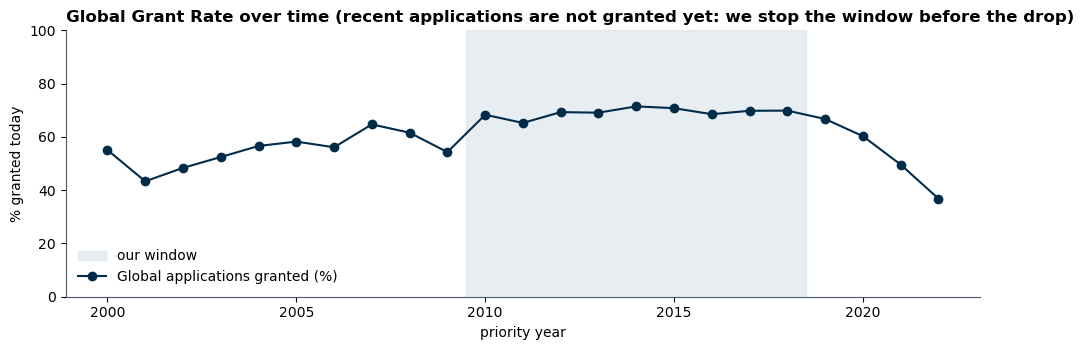

Window 2010-2018: 3,061 families, 7,772 GLOBAL applications


In [3]:
q_apps = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .filter(TLS201_APPLN.earliest_filing_year.between(YEAR_MIN, YEAR_MAX))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)

apps_all = patstat.df(q_apps).drop_duplicates("appln_id")

families_all = (
    apps_all.groupby("docdb_family_id")
          .agg(priority_year=("earliest_filing_year", "min"),
               first_publn_year=("earliest_publn_year", "min"))
          .reset_index()
)


WINDOW = (2010, 2018)       # the priority years we score: see the shaded area

grant_rate = apps_all.groupby("earliest_filing_year").granted.apply(lambda s: (s == "Y").mean())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6, label="our window")
ax.plot(grant_rate.index, grant_rate * 100, marker="o", color=NAVY, label="Global applications granted (%)")
ax.set_ylim(0, 100)
ax.set_xlabel("priority year")
ax.set_ylabel("% granted today")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Global Grant Rate over time (recent applications are not granted yet: we stop the window before the drop)")
plt.tight_layout()
plt.show()

apps = apps_all[apps_all.earliest_filing_year.between(*WINDOW)].copy()
families = families_all[families_all.priority_year.between(*WINDOW)].copy()
FAMILIES = [int(f) for f in families.docdb_family_id]
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(FAMILIES):,} families, {len(apps):,} GLOBAL applications")

## 3. The firms: who owns which family?

The owners are the **applicants** (`applt_seq_nr > 0` in `TLS207`). A family filed by two firms together counts for **both** of them (*full counting*). We read the owners of the whole period, 2000-2022.

PATSTAT's default `psn_name` merges some spelling variants, but it does **not group different legal entities or subsidiaries of the same multinational together**. To solve this, we apply our harmonisation pipeline (`prepare_applicants` from `stage02_clean.py`), which strips legal forms and consolidates the global players specific to the Quantum Computing sector.

In [4]:
!pip install rapidfuzz cleanco


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [5]:
from stage02_clean import prepare_applicants 
from rapidfuzz import fuzz
import unicodedata
import re
from cleanco import basename

clean_owners = prepare_applicants(raw_sector, use_aliases=True, link=True)
clean_owners = clean_owners.rename(columns={
    "unit_id": "docdb_family_id",
    "applicant": "firm"
})

clean_owners = clean_owners[clean_owners["type"] == "firm"].copy() #if we want to consider only firms for our analysis 

print("\nDistribution by type (firm, university, government...):")
print(clean_owners["type"].value_counts(dropna=False))

print("\nTOP 15 PLAYER (after harmonisation) ---")
top_players = clean_owners.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False).head(15)
print(top_players)


Distribution by type (firm, university, government...):
type
firm    9206
Name: count, dtype: int64

TOP 15 PLAYER (after harmonisation) ---
firm
IBM               599
ORIGIN QUANTUM    560
MICROSOFT         213
QUANTUMCTEK       201
D-WAVE SYSTEMS    199
GOOGLE            181
TOSHIBA           180
BAIDU             179
INTEL             154
NEC               133
NTT               129
IONQ              122
STATE GRID        119
FUJITSU           118
HUAWEI            110
Name: docdb_family_id, dtype: int64


### 3.1 Which firms do we score?

We score the top incumbent firms with the most families in our selected time window. This relies on two design choices:

- `N_FIRMS`: how many top firms to retain for the analysis (e.g., for the Magic Quadrant).
- `MIN_FAMILIES`: a minimum portfolio size threshold. With too few families, a single patent's grant or citation drastically swings the average, turning the indicator into noise.

In [6]:
N_FIRMS = 10
MIN_FAMILIES = 10

fam_firm = clean_owners[clean_owners.docdb_family_id.isin(FAMILIES)].copy()

n_families = fam_firm.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False)
TOP = list(n_families[n_families >= MIN_FAMILIES].head(N_FIRMS).index)
SHORT = {f: (f.title()[:28] if len(f) > 5 else f) for f in TOP}     # short names for the charts

print(f"We score {len(TOP)} firms (Top {N_FIRMS} with at least {MIN_FAMILIES} families)")
n_families.loc[TOP].rename("families").to_frame()

We score 10 firms (Top 10 with at least 10 families)


,families
firm,
IBM,150
INTEL,88
GOOGLE,86
TOSHIBA,81
MICROSOFT,76
D-WAVE SYSTEMS,71
QUANTUMCTEK,64
STATE GRID,50
RIGETTI,49


In [7]:
def firm_bars(values, title, xlabel, fmt="{:.2f}", ref=None, ref_label=None, color=NAVY):
    """One horizontal bar per scored firm, in the order of TOP (largest portfolio on top)."""
    v = values.reindex(TOP)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(v) + 1.2))
    ax.barh([SHORT[f] for f in v.index], v.values, color=color)
    for y, x in enumerate(v.values):
        if pd.notna(x):
            ax.text(x, y, (" " + fmt.format(x)) if x >= 0 else (fmt.format(x) + " "), va="center",
                    ha="left" if x >= 0 else "right", fontsize=9, color=GREY)
    if ref is not None:
        ax.axvline(ref, color=ORANGE, ls="--", lw=1.2)
        ax.text(ref, len(v) - 0.45, f" {ref_label}", color=ORANGE, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def per_firm(column, how="mean"):
    """Aggregate a column of `families` over the families of each scored firm."""
    table = fam_firm.merge(families[["docdb_family_id", column]], on="docdb_family_id")
    return table.groupby("firm")[column].agg(how).reindex(TOP).rename(column)

In [9]:
ids = [int(f) for f in fam_firm[fam_firm.firm.isin(TOP)].docdb_family_id.unique()]
q = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
       .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS201_APPLN.appln_id)
       .filter(TLS201_APPLN.docdb_family_id.in_(ids)))
t = patstat.df(q).drop_duplicates("docdb_family_id").merge(
    fam_firm[["docdb_family_id", "firm"]].drop_duplicates(), on="docdb_family_id")
t["mentions_quantum"] = t.appln_title.str.contains("quantum|qubit", case=False)
t = t[t.firm.isin(TOP)]
t.groupby("firm").mentions_quantum.agg(share="mean", families="size").round(2)

,share,families
firm,,
D-WAVE SYSTEMS,0.65,71
GOOGLE,0.77,86
IBM,0.77,150
INTEL,0.90,88
MICROSOFT,0.71,76
NORTHROP GRUMMAN,0.63,41
QUANTUMCTEK,0.66,64
RIGETTI,0.92,49
STATE GRID,0.92,50


In [10]:
COMM = "key distribution|qkd|random number|authentication|encrypt|cryptograph|secure communication|quantum communication|quantum network|quantum key"
t["communication"] = t.appln_title.str.contains(COMM, case=False)
t.groupby("firm").agg(quantum_in_title=("mentions_quantum", "mean"),
                      communication_in_title=("communication", "mean"),
                      families=("communication", "size")).round(2)

,quantum_in_title,communication_in_title,families
firm,,,
D-WAVE SYSTEMS,0.65,0.00,71
GOOGLE,0.77,0.00,86
IBM,0.77,0.02,150
INTEL,0.90,0.01,88
MICROSOFT,0.71,0.04,76
NORTHROP GRUMMAN,0.63,0.00,41
QUANTUMCTEK,0.66,0.67,64
RIGETTI,0.92,0.00,49
STATE GRID,0.92,0.70,50


In [11]:
FOCUS_THRESHOLD = 0.5      # share of titles on key distribution, random numbers, authentication, encryption...
share_comm = t.groupby("firm").communication.mean()
FOCUS = {f: ("communication / security" if share_comm.get(f, 0) >= FOCUS_THRESHOLD else "computing / other")
         for f in TOP}
focus_table = pd.DataFrame({
    "focus": pd.Series(FOCUS),
    "share of titles on communication": share_comm.reindex(TOP).round(2),
    "families (2010-2018)": n_families.reindex(TOP)})
focus_table.rename(index=SHORT)

,focus,share of titles on communication,families (2010-2018)
IBM,computing / other,0.02,150
INTEL,computing / other,0.01,88
Google,computing / other,0.00,86
Toshiba,computing / other,0.36,81
Microsoft,computing / other,0.04,76
D-Wave Systems,computing / other,0.00,71
Quantumctek,communication / security,0.67,64
State Grid,communication / security,0.70,50
Rigetti,computing / other,0.00,49
Northrop Grumman,computing / other,0.00,41


**What do incumbent firms focus on: quantum computing or quantum communication?**

The sector definition from Step 0 includes both quantum computing and quantum communication/security, so all selected firms are retained. We classify each firm's technological focus based on the share of patent titles associated with communication-related technologies, including key distribution, random-number generation, authentication and encryption. This represents a title-based proxy, with a 50% threshold used to distinguish the two technological domains.

The current results identify **eight computing / other firms**: D-Wave Systems, Google, IBM, Intel, Microsoft, Northrop Grumman, Rigetti and Toshiba. Their share of communication-related titles remains below the 50% threshold. In particular, Toshiba shows a relatively higher communication component (36%), but its portfolio is still predominantly classified as computing / other.

The remaining **two firms are mainly communication / security-oriented**:
- **QuantumCTek**, with 67% of patent titles related to communication;
- **State Grid**, with 70% of patent titles related to communication.

These results highlight a predominantly computing-oriented incumbent portfolio, although QuantumCTek and State Grid show a specialization in quantum communication and security technologies.

## 4. Volume: weight in the sector

### 4.1 Basics: share of the sector's families

$$\text{Volume}_f=\frac{\text{families of firm } f}{\text{all families of the sector in the window}}$$

The denominator is **all** the families of the window, including those of individuals, universities and small firms: volume is a share of the whole sector.

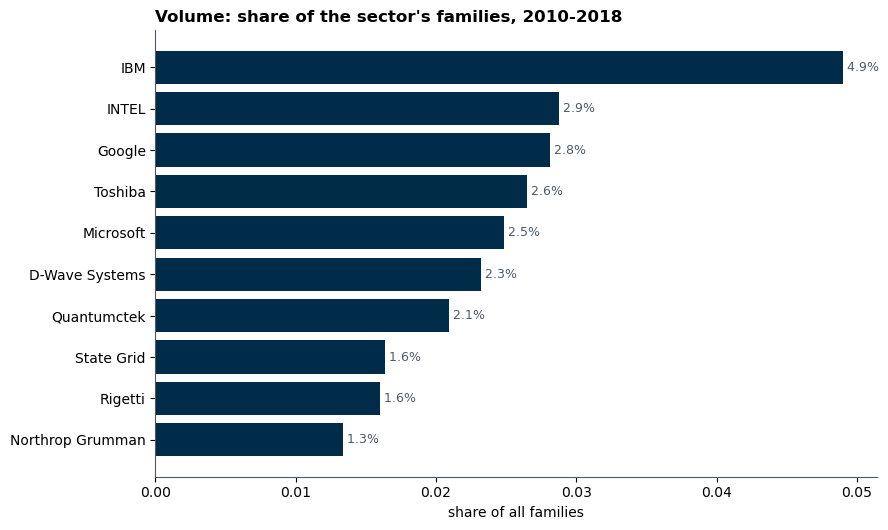

In [8]:
volume = (n_families / len(FAMILIES)).reindex(TOP).rename("volume")
firm_bars(volume, f"Volume: share of the sector's families, {WINDOW[0]}-{WINDOW[1]}", "share of all families", fmt="{:.1%}")

**Reading it.** Only companies are scored (universities and public bodies are left out). IBM is the largest portfolio, but with 4.9% of the families it is far from dominating: the ten firms together hold about a quarter of the sector (756 firm-family links out of 3,061; a family co-owned by two firms counts for both). Intel (2.9%), Google (2.8%), Toshiba (2.6%), Microsoft (2.5%), D-Wave (2.3%) and QuantumCTek (2.1%) are all close to each other. 

**Thinking about..** Volume measures size, not quality: a firm can file many cheap, narrow patents. We complement this metric with additional indicators (influence, success, globalization...) to capture the true technological impact of each portfolio.

### 4.2 Refinement: shares over time, who gains and who loses?

A single average number for the whole period hides the dynamics. The same share, **year by year**, shows changes of power in the sector.

$$\text{Share}_{f,t}=\frac{\text{families of firm } f \text{ with priority year } t}{\text{all families of the sector with priority year } t}$$

We plot it over the whole period, smoothed with a 3-year moving average (one year is often a handful of families). The last two years are incomplete because applications are published 18 months after filing; a share suffers less than a count, but read them with care.

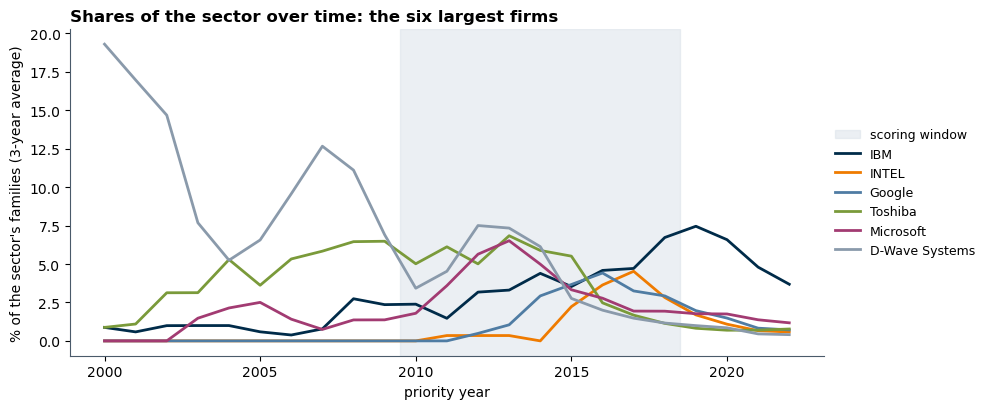

In [9]:
yearly = (clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
                     .groupby(["priority_year", "firm"]).docdb_family_id.nunique()
                     .unstack(fill_value=0))
total = families_all.groupby("priority_year").docdb_family_id.nunique()
share = yearly.reindex(columns=TOP, fill_value=0).div(total, axis=0)
smooth = share.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.5, label="scoring window")
for k, f in enumerate(TOP[:6]):
    ax.plot(smooth.index, smooth[f] * 100, color=LINES[k], lw=2, label=SHORT[f])
ax.set_xlabel("priority year")
ax.set_ylabel("% of the sector's families (3-year average)")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("Shares of the sector over time: the six largest firms")
plt.tight_layout()
plt.show()

To turn the dynamics into a number, the **change of share** inside the window: the average share in the second half (2015-2018) minus the average share in the first half (2010-2014), in percentage points. Positive means the firm is gaining weight.

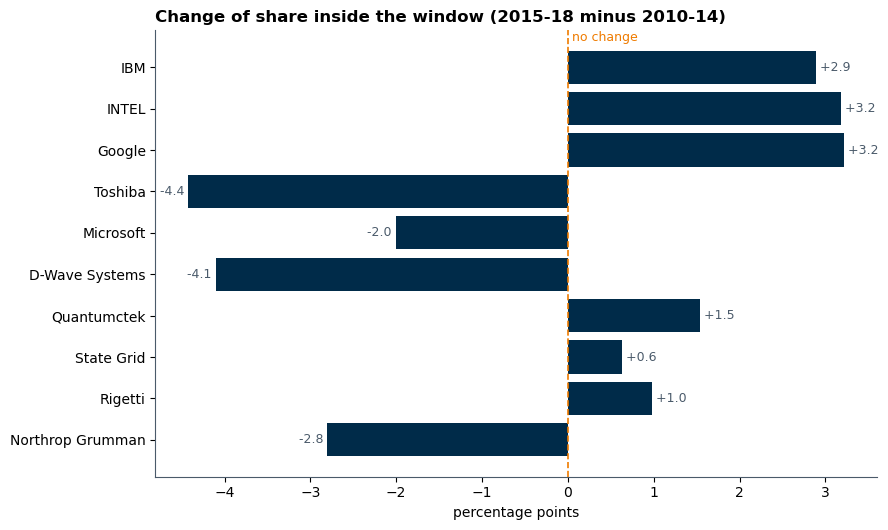

In [10]:
MID_YEAR = WINDOW[0] + (WINDOW[1] - WINDOW[0]) // 2
in_window = share.loc[WINDOW[0]:WINDOW[1]]
volume_change = ((in_window.loc[MID_YEAR + 1:].mean() - in_window.loc[:MID_YEAR].mean()) * 100).rename("volume_change")
firm_bars(volume_change, "Change of share inside the window (2015-18 minus 2010-14)", "percentage points",
          fmt="{:+.1f}", ref=0, ref_label="no change")

**Reading it.** The shares move a lot inside the window, and the leaders of the early 2010s are not those of 2018:
 
- **gaining weight**: Google (+3.2 percentage points between 2010-14 and 2015-18), Intel (+3.2, from almost nothing before 2014), IBM (+2.9), then QuantumCTek (+1.5), Rigetti (+1.0) and State Grid (+0.6);
- **losing weight**: Toshiba (-4.4), D-Wave (-4.1), Northrop Grumman (-2.8) and Microsoft (-2.0). D-Wave and Toshiba were the largest of the six in the first years (D-Wave alone had about 7% of the sector's families in 2012-13, and almost 20% in 2000), and they lose share because the sector grows around them, not because they stop filing.
The chart also shows the limit of our window: after 2019 the shares of all the six largest firms fall.

### 4.3 Refinement: Recent Momentum (Who is accelerating in the last 3 years of our window?)

A firm might have a large historical portfolio but low recent activity, or vice versa. To capture who is driving the current wave of Quantum Computing innovation, we measure **Recent Momentum**: the share of an enterprise's total portfolio filed in the most recent years of the window considered for the anlysis.

$$\text{Momentum}_{f}=\frac{\text{families of firm f}}{\text{total families of firm f in the window}}$$

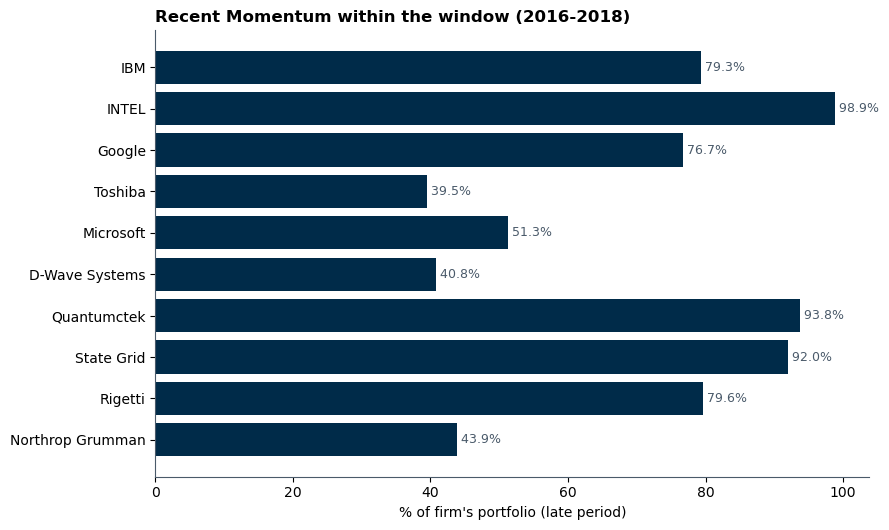

In [11]:
RECENT_WINDOW_START = 2016  # we consider as recent years, the last years of our considered window 

firm_with_years = clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
firm_in_window = firm_with_years[firm_with_years.docdb_family_id.isin(FAMILIES)]

recent_vol = firm_in_window[firm_in_window.priority_year >= RECENT_WINDOW_START].groupby("firm").docdb_family_id.nunique()
total_vol = firm_in_window.groupby("firm").docdb_family_id.nunique()

recent_momentum = ((recent_vol / total_vol) * 100).reindex(TOP).fillna(0).rename("recent_momentum") # % recents patents / 

firm_bars(
    recent_momentum, 
    f"Recent Momentum within the window ({RECENT_WINDOW_START}-{WINDOW[1]})", 
    "% of firm's portfolio (late period)", 
    fmt="{:.1f}%"
)

**Reading it.** Momentum is the share of a firm's portfolio filed in 2016-18, the last three years of the window. It is high for Intel (99%), QuantumCTek (94%) and State Grid (92%): almost their whole portfolio is recent, as they started filing seriously only in the second half of the 2010s. IBM, Rigetti and Google are in between (77-80%), while Microsoft (51%), Northrop Grumman (44%), D-Wave (41%) and Toshiba (40%) have a long history, with more than half of their families before 2016. Since the sector itself grows, 33% (three years out of nine) is not the neutral value: a firm is "accelerating" only if it is clearly above the sector.

**Volume in short** The sector is fragmented: the largest firm (IBM) has 4.9% of the families and the ten firms together about a quarter. The leaders change inside the window: Google, Intel and IBM gain share, Toshiba, D-Wave, Microsoft and Northrop Grumman lose it.

## 5. Influence: technological impact

### 5.1 Basics: forward citations within 5 years, compared with the same year

A family is influential if later inventions **build on it**, so we count its forward citations:

- **between families**: `TLS228_DOCDB_FAM_CITN` has one row per pair *citing family → cited family*, collecting the citations made by any publication of one family to any publication of the other;
- **within 5 years** of the first publication of the cited family, so that old and young families have the same time to be cited. The date of a citation is the first publication year of the **citing** family;
- we drop a family citing itself; citations from the same firm (self-citations) stay in, as in the OECD indicators.

First, the citations and their dates:

In [12]:
q = db.query(
    TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
    TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited_family"),
).filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(FAMILIES))

fcit = patstat.df(q)
fcit = fcit[fcit.citing_family != fcit.cited_family]

q_cit = (
    db.query(TLS201_APPLN.docdb_family_id, func.min(TLS201_APPLN.earliest_publn_year).label("year"))
    .filter(TLS201_APPLN.docdb_family_id.in_([int(f) for f in fcit.citing_family.unique()]))
    .filter(TLS201_APPLN.earliest_publn_year < 9999)
    .group_by(TLS201_APPLN.docdb_family_id)
)

fcit["citing_year"] = fcit.citing_family.map(patstat.df(q_cit).set_index("docdb_family_id").year)
fcit["cited_year"] = fcit.cited_family.map(families.set_index("docdb_family_id").first_publn_year)
fcit["lag"] = fcit.citing_year - fcit.cited_year         # years between the two first publications

print(f"{len(fcit):,} citing-cited pairs, from {fcit.citing_family.nunique():,} citing families")

53,013 citing-cited pairs, from 20,706 citing families


A raw count is unfair across years: older families had more citing patents around them and more time in the data. So we divide each family's count by the **mean of the families with the same priority year** $t$.

What about the **field**? Citation habits differ a lot between fields, so in general the comparison should be made within the same field and year. Here all families belong to our defined **Quantum Computing sector**: the technological scope is fixed by our sector boundary, and comparing within the year **is** like comparing within field and year.

$$\text{fwd}^{norm}_{i}=\frac{\text{fwd}_{i}}{\bar F_{t}}\qquad\text{with}\qquad \bar F_{t}=\frac{1}{N_{t}}\sum_{j\,\in\,t}\text{fwd}_{j}$$

- $\text{fwd}_i$: citations received by family $i$ within 5 years; $t$ is its priority year;
- $N_{t}$: the number of families of the sector with priority year $t$.

A value of **1** means "cited as much as the average family of the sector filed in the same year"; 2 means twice as much.

We write it as a function of the window `w`, because the refinements use other windows. A window is counted only if the data cover it: PATSTAT Spring 2026 has the citations up to about 2025 (`LAST_YEAR`), so a family first published in 2022 has no complete 5-year window, and its value is set to *missing* rather than to a count that is too low.

In [13]:
LAST_YEAR = 2025                      # last year of citations covered by the PATSTAT edition
COHORT = ["priority_year"]            # comparing based on priority year within our sector


def forward_citations(w):
    """Citations received within w years of the first publication; missing if the window is not complete."""
    counts = fcit[fcit.lag.between(0, w)].groupby("cited_family").citing_family.nunique()
    fwd = families.docdb_family_id.map(counts).fillna(0)
    complete = families.first_publn_year + w <= LAST_YEAR
    return fwd.where(complete)


def normalise_by_cohort(values):
    """Each family's value divided by the mean of the families with the same priority year."""
    mean_cohort = values.groupby([families[c] for c in COHORT]).transform("mean")
    return (values / mean_cohort).where(mean_cohort > 0, 0.0).where(values.notna())


families["fwd5"] = forward_citations(5)
families["fwd5_norm"] = normalise_by_cohort(families.fwd5)
families.groupby("priority_year").fwd5.mean().round(2).to_frame("mean fwd5 (the denominator)").T

priority_year,2010,2011,2012,2013,2014,2015,2016,2017,2018
mean fwd5 (the denominator),6.83,11.99,10.64,16.1,16.04,18.92,17.41,12.33,10.11


Read the means by year: they move from year to year, and they fall in the last years because younger families are cited less or the data stop. The normalisation removes this, because each family is compared only with the families of its own year. The influence of a firm is the **average** of its families:

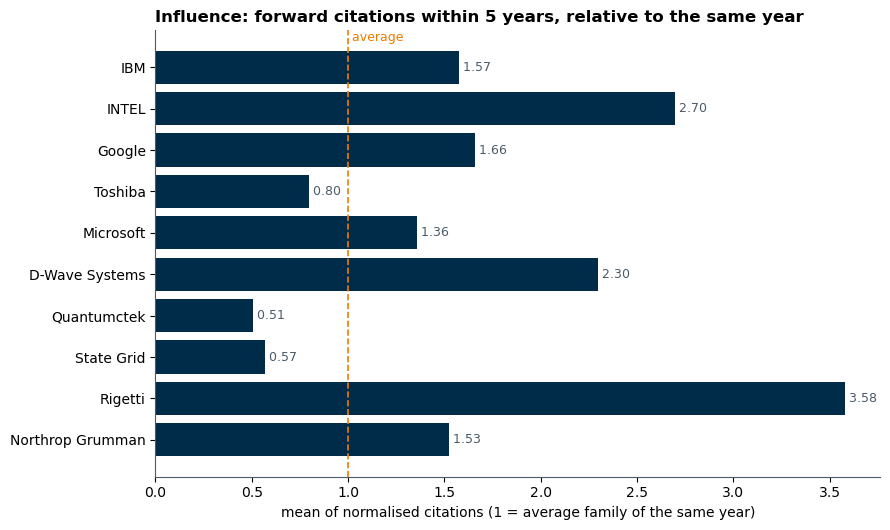

In [14]:
influence = per_firm("fwd5_norm").rename("influence")
firm_bars(influence, "Influence: forward citations within 5 years, relative to the same year",
          "mean of normalised citations (1 = average family of the same year)", ref=1, ref_label="average")

**Reading it.** Seven firms are above the average family of their year: Rigetti (3.58), Intel (2.70), D-Wave (2.30), Google (1.66), IBM (1.57), Northrop Grumman (1.53) and Microsoft (1.36). Toshiba (0.80), State Grid (0.57) and QuantumCTek (0.51) are below. Volume and influence are different things: IBM has the largest portfolio but is only fifth on influence, while Rigetti has 49 families and the highest value. With so few families an average is fragile: two of the ten strongest families of the sector are Rigetti's (5.4), so its first place depends on a few star families. The low values of the two Chinese firms and Toshiba may also come from the habits of citation of their offices and from the quantum communication block (QKD) they file in, and not from lower quality.

**Watch out.** An average is pulled up by one star family: a firm with 9 uncited families and one blockbuster can look influential. Refinement 5.4 looks at the top of the distribution instead.

### 5.2 Refinement: a shorter or a longer window (3 and 7 years)

A short window measures how fast a family is noticed; a long one is closer to its total impact, but the last priority years have no complete window yet, so it rests on the older families only. Does the window change the story?

In [15]:
for w in [3, 7]:
    families[f"fwd{w}_norm"] = normalise_by_cohort(forward_citations(w))

by_window = pd.concat([per_firm(f"fwd{w}_norm") for w in [3, 5, 7]], axis=1)
by_window.columns = ["3 years", "5 years", "7 years"]
print("Families with a complete window:",
      {w: f"{families[f'fwd{w}_norm'].notna().mean():.0%}" for w in [3, 5, 7]})
print("Rank correlation with the 5-year ranking:",
      by_window.corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
by_window.rename(index=SHORT).round(2)

Families with a complete window: {3: '99%', 5: '98%', 7: '66%'}
Rank correlation with the 5-year ranking: {'3 years': 0.94, '7 years': 0.98}


,3 years,5 years,7 years
firm,,,
IBM,1.60,1.57,1.68
INTEL,3.23,2.70,2.48
Google,1.46,1.66,1.83
Toshiba,0.70,0.80,0.95
Microsoft,1.25,1.36,1.49
D-Wave Systems,2.18,2.30,2.40
Quantumctek,0.50,0.51,0.64
State Grid,0.50,0.57,1.04
Rigetti,3.18,3.58,4.58


**Reading it.** The window changes the story: the order of the firms with 3 and 7 years has a rank correlation of 0.94 and 0.98 with the order with 5 years (for 7 years only 66% of the families have a complete window, so the 7-year column rests on the older families). The differences are in the speed of the citations: Intel is cited fast (3.23 with 3 years, 2.48 with 7), so its advantage shrinks with time, while Rigetti (3.18 to 4.58), Google (1.46 to 1.83) and State Grid (0.50 to 1.04) are noticed later and keep being cited. IBM and Microsoft hardly move. We keep 5 years as the basic window.

If the order of the firms is the same in the three columns, the choice of the window does not matter much. A firm that climbs with the longer window has patents noticed late but used for long.

### 5.3 Refinement: who cites the firm, competitors or examiners?

A citation can be added by the **applicant** of the citing patent (origin `APP` in `TLS212`) or by the **examiner** during the search or examination (`SEA`, `ISR`, `SUP`, `EXA`...). The difference matters:

- an **applicant** citation means that a competitor *knew* the patent when it filed: a real knowledge flow, and visibility in the market;
- an **examiner** citation means that the patent is relevant prior art, which the citing applicant may never have read.

The origin is recorded at the level of **publications**, so we go from our global families to their publications (`TLS211`), then to the publications that cite them. We keep only citing **EP** publications: at the USPTO applicants must disclose all the prior art they know, so US applicant citations would mix different legal practices.

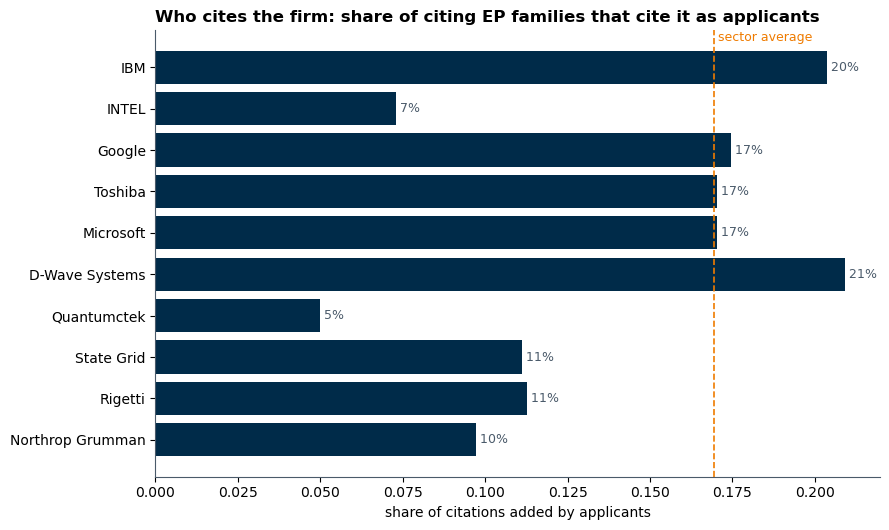

In [16]:
CITING_OFFICES = ["EP"]

# 1. All the publications of the families of the window (any office)
q = (db.query(TLS211_PAT_PUBLN.pat_publn_id, TLS201_APPLN.docdb_family_id.label("cited_family"))
     .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
     .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES)))
pubs = patstat.df(q)

# 2. The citations they receive, with their origin
q = (
    db.query(TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished,
             TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id)
    .filter(TLS212_CITATION.cited_pat_publn_id.in_([int(p) for p in pubs.pat_publn_id]))
)
cit = patstat.df(q)
cit["cited_family"] = cit.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").cited_family)

# 3. The office and the family of each citing publication
q = (
    db.query(TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
             TLS201_APPLN.docdb_family_id.label("citing_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
cit = cit.merge(patstat.df(q), on="citing_publn")
cit = cit[cit.citing_family != cit.cited_family]
cit["who"] = np.where(cit.citn_origin.str.strip() == "APP", "applicant", "examiner or other")

ep_cit = (cit[cit.citing_office.isin(CITING_OFFICES)]
          .drop_duplicates(["citing_family", "cited_family", "who"])
          .merge(fam_firm, left_on="cited_family", right_on="docdb_family_id"))
applicant_share = (ep_cit.who == "applicant").groupby(ep_cit.firm).mean().reindex(TOP).rename("applicant_share")
firm_bars(applicant_share, "Who cites the firm: share of citing EP families that cite it as applicants",
          "share of citations added by applicants", fmt="{:.0%}",
          ref=(ep_cit.who == "applicant").mean(), ref_label="sector average")

**Reading it.** On average 17% of the EP citations of the sector are added by the applicants. D-Wave (21%) and IBM (20%) are above it: their patents are known reference points that competitors cite on their own. Google, Toshiba and Microsoft are at the average (17%). Intel (7%) and QuantumCTek (5%) are far below: Intel is the second most cited firm in 5.1, but mostly by examiners, so its patents appear as relevant prior art in the search reports and not necessarily as a source competitors were reading. Only EP citing families are used, so the figure for the Chinese firms rests on few citations.

A firm with a high applicant share is **watched by its competitors**: its patents are known reference points (read it with the number of citations)

### 5.4 Refinement: blocking patents, X and I citations at the top of the sector

Not all citations are equal. In a search report the examiner gives each cited document a **category** (`TLS215_CITN_CATEG`):

| Category | Meaning for the citing application |
|---|---|
| **X** | the cited document **alone** destroys the novelty or the inventive step of the claim |
| **I** | the cited document **alone** destroys the inventive step of the claim (EPO, since 2012) |
| Y | relevant only in combination with another document |
| A | general background |

A family often cited as **X or I** stood in the way of later applications: competitors had to narrow their claims or give up. It is a **blocking patent**, the strongest form of influence. `CITN_CATEG` can hold several letters (e.g. `XI`), so we look for an X or an I anywhere in it.

For each family we count the distinct families that cite it as X or I, and we call **blocking** the families in the **top 10% of their priority year**, with at least one such citation. As in 5.1, comparing inside the year is fair to young families, and the field is fixed by our global sector boundary.

Each family is then **blocking (1) or not (0)**. For a firm we compute two numbers from these 0/1 values:

$$\text{Blocking share}_f=\frac{\text{blocking families of } f}{\text{families of } f}\qquad\qquad \text{Share of the sector's blocking}_f=\frac{\text{blocking families of } f}{\text{all blocking families of the sector}}$$

The first is the average of the 0/1 values over the firm's families: the share of its portfolio that blocks others.

In [17]:
TOP_SHARE = 0.10              # top 10% of each priority year

q = (
    db.query(TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished,
             TLS215_CITN_CATEG.citn_id, TLS215_CITN_CATEG.citn_categ)
    .filter(TLS215_CITN_CATEG.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
categ = patstat.df(q)
xi_keys = categ[categ.citn_categ.str.contains("X|I", regex=True)][["citing_publn", "citn_replenished", "citn_id"]]
xi = cit.merge(xi_keys.drop_duplicates(), on=["citing_publn", "citn_replenished", "citn_id"])

families["xi"] = families.docdb_family_id.map(xi.groupby("cited_family").citing_family.nunique()).fillna(0)
threshold = families.groupby(COHORT).xi.transform(lambda s: s.quantile(1 - TOP_SHARE))   # cut-off of each year
families["blocking"] = ((families.xi > threshold) & (families.xi > 0)).astype(int)

owners_of = fam_firm.groupby("docdb_family_id").firm.agg(", ".join)     # co-owned families: all owners
print(f"Blocking families: {families.blocking.sum():,} of {len(families):,}. The ten strongest:")
(families.assign(owners=families.docdb_family_id.map(owners_of).fillna("(not a company)"))
         .sort_values("xi", ascending=False)[["docdb_family_id", "priority_year", "xi", "owners"]].head(10))

Blocking families: 239 of 3,061. The ten strongest:


,docdb_family_id,priority_year,xi,owners
1292,54554938,2014,20.0,RIGETTI
2091,60935992,2017,11.0,GOOGLE
918,47992613,2011,9.0,LOS ALAMOS NATIONAL SECURITY
1722,58662742,2015,9.0,(not a company)
3419,67301223,2018,9.0,BIOVENTURES
2267,62075687,2016,8.0,HUAWEI
3848,68766205,2018,8.0,ATOM COMPUTING
1195,52997221,2015,8.0,HITACHI
1111,52007585,2013,8.0,"QUANTUM COMMUNICATION TECHNOLOGY, QUANTUM..."
2272,62091366,2015,8.0,RIGETTI


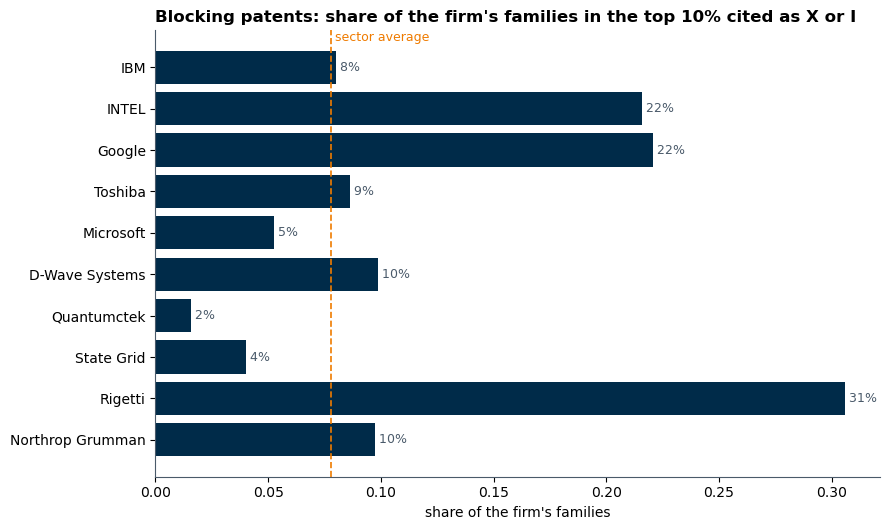

,blocking families,blocking_share,share_of_sector_blocking
firm,,,
IBM,12,0.08,0.05
INTEL,19,0.22,0.08
Google,19,0.22,0.08
Toshiba,7,0.09,0.03
Microsoft,4,0.05,0.02
D-Wave Systems,7,0.10,0.03
Quantumctek,1,0.02,0.00
State Grid,2,0.04,0.01
Rigetti,15,0.31,0.06


In [18]:
blocking_share = per_firm("blocking").rename("blocking_share")                 # mean of 0/1 = share of families
blocking_power = (per_firm("blocking", "sum") / families.blocking.sum()).rename("share_of_sector_blocking")

firm_bars(blocking_share, f"Blocking patents: share of the firm's families in the top {TOP_SHARE:.0%} cited as X or I",
          "share of the firm's families", fmt="{:.0%}", ref=families.blocking.mean(), ref_label="sector average")
pd.concat([per_firm("blocking", "sum").rename("blocking families"), blocking_share, blocking_power],
          axis=1).rename(index=SHORT).round(2)

`blocking_share` is the **quality** of the portfolio (how many of its families block others), `share_of_sector_blocking` is the **power** in the sector (how many of the sector's blocking patents the firm owns).


**Reading it.** 239 of the 3,061 families (7.8%) are blocking: in the top 10% of their year and cited at least once as X or I. Rigetti has the highest share (31% of its families, 15 families), followed by Intel and Google (22% each, 19 families, 8% of all the blocking patents of the sector each). IBM, the largest portfolio, has 12 blocking families (8% of its portfolio): size does not give blocking power. Microsoft (5%), State Grid (4%) and QuantumCTek (2%, one family) are at the bottom. The strongest family of the sector belongs to Rigetti (2014, 20 families cite it as X or I, against 11 for the second, a Google family of 2017). The categories X and I come from the search reports of the EPO and the PCT, so the indicator sees better the firms that file there.

### 5.5 Refinement: backward citations and citations to science

While forward citations measure future impact, **backward citations** and **non-patent literature (NPL) citations** measure the foundations of the invention:

- **Backward citations:** The number of earlier patent documents cited by the invention (excluding NPL, self-citations included). A high count indicates that the patent underwent rigorous screening against an extensive prior art landscape, reflecting technological solidity.
- **Citations to science (NPL):** Links to scientific papers and non-patent literature (`cited_npl_publn_id > 0`). In fields like Quantum Computing, inventions tightly coupled with academic and scientific literature tend to be more radical and of higher technological quality.

As with forward citations, we normalise these metrics by priority year cohort to account for generational differences in citation intensity.

npl_type
a    33838
s     5652
w     1002
b      257
e        3
d        1
Name: count, dtype: int64


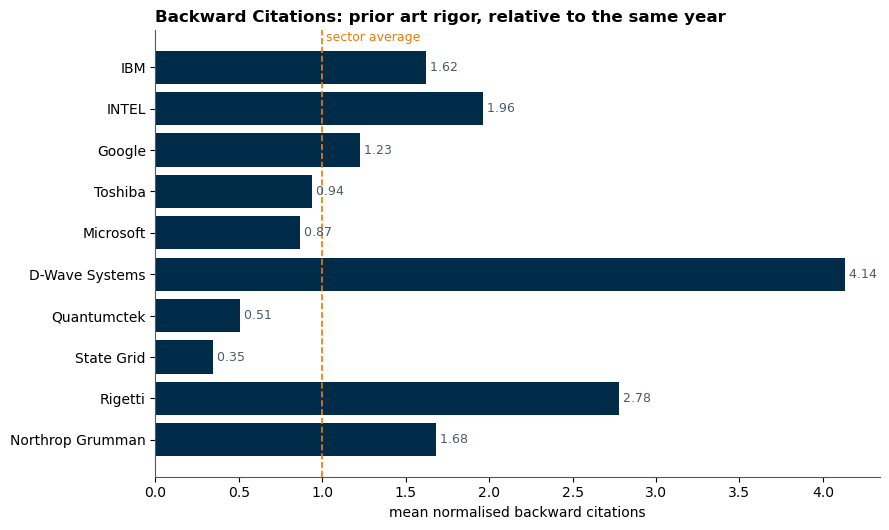

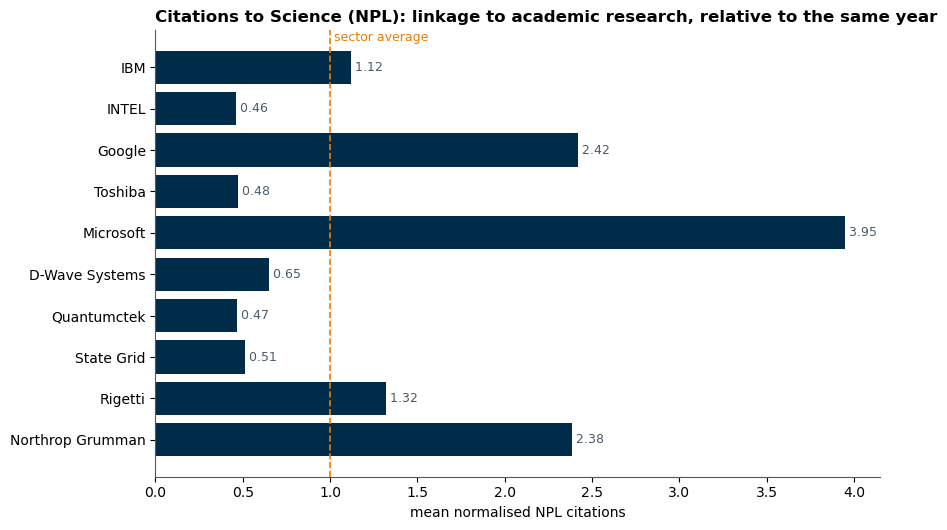

,backward_citations,science_citations
firm,,
IBM,1.62,1.12
INTEL,1.96,0.46
Google,1.23,2.42
Toshiba,0.94,0.48
Microsoft,0.87,3.95
D-Wave Systems,4.14,0.65
Quantumctek,0.51,0.47
State Grid,0.35,0.51
Rigetti,2.78,1.32


In [19]:
# Backward Patent Citations per family (excluding NPL)
q_back = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("citing_family"),
        TLS212_CITATION.pat_publn_id,
        TLS212_CITATION.cited_pat_publn_id,
        TLS212_CITATION.cited_npl_publn_id
    )
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.pat_publn_id == TLS212_CITATION.pat_publn_id)
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
)
back_df = patstat.df(q_back)

back_df["cited_pat_publn_id"] = pd.to_numeric(back_df["cited_pat_publn_id"], errors="coerce").fillna(0)
back_df["cited_npl_publn_id"] = pd.to_numeric(back_df["cited_npl_publn_id"], errors="coerce").fillna(0)

back_pat = back_df[back_df.cited_pat_publn_id > 0].groupby("citing_family").cited_pat_publn_id.nunique()
families["back_citations"] = families.docdb_family_id.map(back_pat).fillna(0)

# Citations to science (NPL) per family 
q_npl = (
    db.query(TLS201_APPLN.docdb_family_id.label("citing_family"),
             TLS214_NPL_PUBLN.npl_publn_id, TLS214_NPL_PUBLN.npl_type)
    .select_from(TLS201_APPLN)
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
    .join(TLS214_NPL_PUBLN, TLS214_NPL_PUBLN.npl_publn_id == TLS212_CITATION.cited_npl_publn_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS212_CITATION.cited_npl_publn_id != "0")  
    .distinct()
)
npl = patstat.df(q_npl)
npl = npl[~npl.npl_publn_id.astype(str).str.strip().isin(["", "0"])]
print(npl.npl_type.value_counts())          # check which type are the journal articles
# scientific = articles only ("s" in the tutorial); not all NPL is science
sci = npl[npl.npl_type == "s"]
families["sci_citations"] = families.docdb_family_id.map(sci.groupby("citing_family").npl_publn_id.nunique()).fillna(0)


families["back_norm"] = normalise_by_cohort(families.back_citations)
families["sci_norm"] = normalise_by_cohort(families.sci_citations)

back_firm = per_firm("back_norm").rename("backward_citations")
sci_firm = per_firm("sci_norm").rename("science_citations")

firm_bars(back_firm, "Backward Citations: prior art rigor, relative to the same year", 
          "mean normalised backward citations", ref=1, ref_label="sector average")

firm_bars(sci_firm, "Citations to Science (NPL): linkage to academic research, relative to the same year", 
          "mean normalised NPL citations", ref=1, ref_label="sector average")

pd.concat([back_firm, sci_firm], axis=1).rename(index=SHORT).round(2)

**Reading it.** Of the 40,753 non-patent references of the sector only the 5,652 of type `s` (journal articles) are counted as science.
 
- **Backward citations** are highest for D-Wave (4.14) and Rigetti (2.78), lowest for QuantumCTek (0.51) and State Grid (0.35). They depend a lot on the practice of the office (US applicants list many references, Chinese ones few), so we read them as a description and not as a quality ranking.
- **Citations to science** separate the firms more clearly: Microsoft (3.95), Google (2.42) and Northrop Grumman (2.38) build on academic literature much more than the average, Intel (0.46), QuantumCTek (0.47) and Toshiba (0.48) much less. Intel is cited a lot but cites little science: its influence comes from applied hardware, not from research close to the papers.

### 5.6 Refinement: Originality and Generality

To understand the structural nature of a firm's technology portfolio, we compute two classic indexes based on CPC/IPC technological classes (using the Herfindahl-Hirschman dispersion index $1 - \sum s_{ik}^2$):

- **Originality:** Measures how widely recombinant an invention is. A high originality score means the patent builds upon prior art drawn from many different, distant technological fields.
- **Generality:** Measures how widely a patent is applied later. A high generality score means the patent is cited by subsequent inventions spanning a broad range of diverse technological fields, acting much like a General-Purpose Technology (GPT).

Both metrics are aggregated at the firm level to evaluate the breadth of their R&D output.

Families with a value: {'originality': 0.65, 'generality': 0.64}


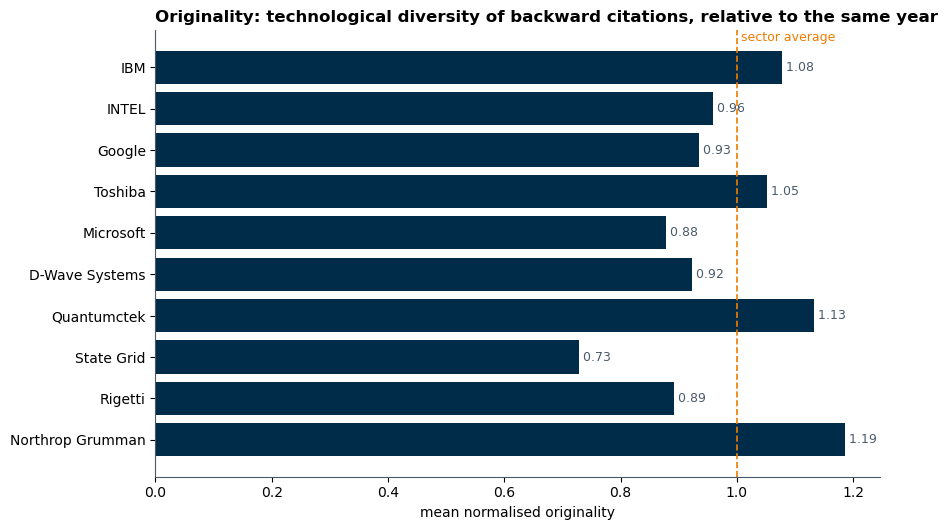

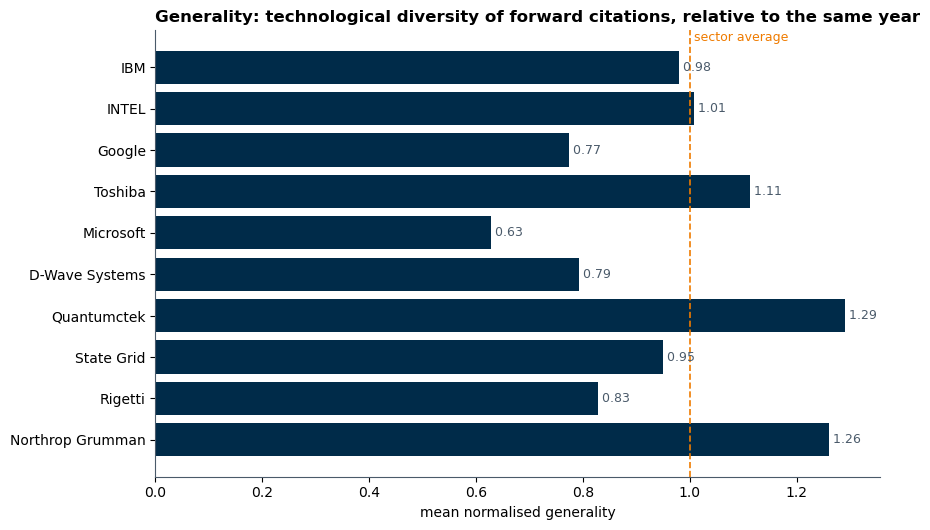

,originality,generality
firm,,
IBM,1.08,0.98
INTEL,0.96,1.01
Google,0.93,0.77
Toshiba,1.05,1.11
Microsoft,0.88,0.63
D-Wave Systems,0.92,0.79
Quantumctek,1.13,1.29
State Grid,0.73,0.95
Rigetti,0.89,0.83


In [20]:
def family_fields(family_ids):
    """WIPO field shares of each DOCDB family (weights summed over its applications)."""
    ids, out = [int(i) for i in family_ids], []
    for s in range(0, len(ids), 5000):
        q = (db.query(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                      func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w"))
             .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
             .filter(TLS201_APPLN.docdb_family_id.in_(ids[s:s + 5000]))
             .group_by(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr))
        out.append(patstat.df(q))
    f = pd.concat(out)
    f["w"] = f.w.astype(float)
    f["w"] = f.w / f.groupby("docdb_family_id").w.transform("sum")
    return f


def dispersion(pairs, key, other, fields, min_n=5):
    """1 - sum of squared field shares over the `other` families linked to `key`.
    Hall-Jaffe correction n/(n-1); NaN below min_n links (the index is unstable)."""
    t = pairs.merge(fields.rename(columns={"docdb_family_id": other}), on=other)
    w = t.groupby([key, "techn_field_nr"]).w.sum().reset_index()
    w["s"] = w.w / w.groupby(key).w.transform("sum")
    d = 1 - (w.s ** 2).groupby(w[key]).sum()
    n = pairs.groupby(key)[other].nunique().reindex(d.index)
    return (d * n / (n - 1)).where(n >= min_n)

# 1. ORIGINALITY (Based on Backward Citations) Map cited publications -> families
cited_pubs = back_df.loc[back_df.cited_pat_publn_id > 0, "cited_pat_publn_id"].astype("int64").unique()
maps = []
for s in range(0, len(cited_pubs), 5000):
    q = (db.query(TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"),
                  TLS201_APPLN.docdb_family_id.label("cited_family"))
         .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
         .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cited_pubs[s:s + 5000]])))
    maps.append(patstat.df(q))
pub2fam = pd.concat(maps).drop_duplicates("cited_pat_publn_id")

b = back_df[back_df.cited_pat_publn_id > 0].copy()
b["cited_pat_publn_id"] = b.cited_pat_publn_id.astype("int64")
back_pairs = (b.merge(pub2fam, on="cited_pat_publn_id")[["citing_family", "cited_family"]]
                .drop_duplicates().query("citing_family != cited_family"))


# 2. GENERALITY (Based on Forward Citations) citing families within 5 years (same window as influence)
fwd_pairs = fcit[fcit.lag.between(0, 5)][["citing_family", "cited_family"]].drop_duplicates()

fields = family_fields(set(back_pairs.cited_family) | set(fwd_pairs.citing_family))

families["originality"] = families.docdb_family_id.map(dispersion(back_pairs, "citing_family", "cited_family", fields))
families["generality"] = families.docdb_family_id.map(dispersion(fwd_pairs, "cited_family", "citing_family", fields))
families["orig_norm"] = normalise_by_cohort(families.originality)
families["gen_norm"] = normalise_by_cohort(families.generality)
print("Families with a value:", families[["originality", "generality"]].notna().mean().round(2).to_dict())

orig_firm = per_firm("orig_norm").rename("originality")
gen_firm = per_firm("gen_norm").rename("generality")

firm_bars(
    orig_firm, 
    "Originality: technological diversity of backward citations, relative to the same year", 
    "mean normalised originality", 
    ref=1, 
    ref_label="sector average"
)

firm_bars(
    gen_firm, 
    "Generality: technological diversity of forward citations, relative to the same year", 
    "mean normalised generality", 
    ref=1, 
    ref_label="sector average"
)

orig_firm.rename(index=SHORT).round(2)
gen_firm.rename(index=SHORT).round(2)
pd.concat([orig_firm, gen_firm], axis=1).rename(index=SHORT).round(2)


In [21]:
n_used = (fam_firm.merge(families[["docdb_family_id", "orig_norm", "gen_norm"]], on="docdb_family_id")
                  .groupby("firm")[["orig_norm", "gen_norm"]].count()
                  .reindex(TOP)
                  .rename(columns={"orig_norm": "n families with originality",
                                   "gen_norm": "n families with generality"}))
n_used["families in the window"] = n_families.reindex(TOP)

n_used.rename(index=SHORT)

,n families with originality,n families with generality,families in the window
firm,,,
IBM,145,135,150
INTEL,79,87,88
Google,78,83,86
Toshiba,68,59,81
Microsoft,56,71,76
D-Wave Systems,65,70,71
Quantumctek,37,27,64
State Grid,23,20,50
Rigetti,46,46,49


**Reading it.** The two indexes are computed only for families with at least 5 links (65% of the families for originality, 64% for generality), so the number of families used for each firm matters: it is lowest for State Grid (23 and 20 of 50) and QuantumCTek (37 and 27 of 64), whose values are the least reliable. Northrop Grumman (1.19 and 1.26), QuantumCTek (1.13 and 1.29) and Toshiba (1.05 and 1.11) are above the average on both, while Microsoft (0.88 and 0.63), Google (0.93 and 0.77) and D-Wave (0.92 and 0.79) are below on generality: their patents are cited by a narrower set of technology fields. The differences are small (0.63 to 1.29) and the 35 WIPO fields are coarse, so we read groups of firms and not single positions. The high values of QuantumCTek are probably due to its QKD families, which mix computing, optics and communication. Generality exists only for families cited at least 5 times, so it is tied to influence.

**Influence in short** Size is not impact. Rigetti, Intel and D-Wave are the most cited relative to their year, IBM and Google are above the average, and Toshiba, State Grid and QuantumCTek are below. The ranking is stable with the 3, 5 and 7-year windows (correlations 0.94 and 0.98). Behind the numbers there are different stories: Rigetti depends on a few star families, Intel is cited mostly by examiners, D-Wave and IBM are cited by competitors, Microsoft and Google rely most on academic literature.

## 6. Success: quality as judged by the examiners

Success asks: **when the firm applies for a patent, do the examiners accept it?** A granted patent has passed an examination of novelty and inventive step, so a high grant rate signals inventions of good quality and well-drafted applications. 

### 6.1 Basics: share of global applications granted

Because many firms in our global dataset do not restrict their filings to the EPO, measuring success exclusively through European applications would create a bias. Instead, we compute the success rate across all national and regional patent offices where the firm files:

$$\text{Success}_f=\frac{\text{granted global applications of firm } f}{\text{global applications of firm } f}$$

`granted` is `Y` when PATSTAT has an indication of a grant, `N` otherwise. `N` therefore mixes refused, withdrawn and still pending applications; with the window ending in 2018 most applications have been decided. 
To focus purely on active substantive examinations, we exclude:
- **`WO`**: a PCT application is a request, not protection in a country;
- **`T`** (`appln_kind` in `TLS201`): translations of granted EP patents recorded as national applications in certain countries (Spain, Portugal, Poland, Denmark, Austria, etc.), which are always "granted" by default and counting it would inflate both success and globalization.

In [22]:
q = (
    db.query(
        TLS201_APPLN.appln_id, 
        TLS201_APPLN.docdb_family_id, 
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind, 
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
members = patstat.df(q).drop_duplicates("appln_id")

# national applications: exclude PCT requests (WO) and translations of EP patents (kind T)
national = members[(members.appln_auth != "WO") & (members.appln_kind != "T")]

office_rate = national.groupby("appln_auth").agg(
    applications=("appln_id", "size"),
    granted=("granted", lambda s: (s == "Y").mean())
)
display(office_rate[office_rate.applications >= 20].sort_values("granted", ascending=False).round(2).T)

appln_auth,ES,RU,FR,AU,US,JP,TW,KR,CN,EP,CA,GB,IL,DE,SG
applications,64.0,24.0,26.00,242.00,2366.00,595.00,50.00,354.0,1677.00,709.00,260.00,147.00,20.0,80.00,45.0
granted,1.0,1.0,0.96,0.88,0.87,0.87,0.84,0.8,0.73,0.68,0.65,0.63,0.4,0.36,0.0


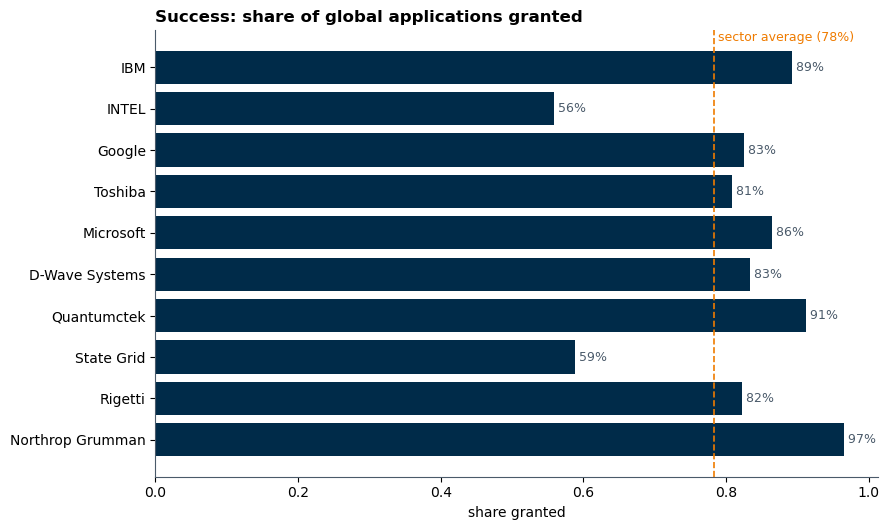

In [23]:
global_apps = national.merge(fam_firm, on="docdb_family_id")

success_global = global_apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean()).reindex(TOP).rename("success_global")
sector_rate_global = (national.granted == "Y").mean()

firm_bars(
    success_global, 
    "Success: share of global applications granted", 
    "share granted", 
    fmt="{:.0%}",
    ref=sector_rate_global, 
    ref_label=f"sector average ({sector_rate_global:.0%})"
)

**Reading it.** The sector average is 78% of the applications granted. Northrop Grumman (97%), QuantumCTek (91%) and IBM (89%) are the highest; Microsoft, Google, D-Wave, Rigetti and Toshiba are between 81% and 86%; Intel (56%) and State Grid (59%) are clearly apart. The table of the offices shows why the office mix matters: the grant rate is 87% in the US and Japan, 73% in China and 68% at the EPO. Yet the two Chinese firms are at opposite ends (91% against 59%), so the office does not explain everything. For Intel and State Grid more than 90% of the families were filed in 2016-18, and some of these applications may still be pending (they are counted as not granted).

### 6.2 Refinement: success across offices, invention by invention

Offices apply different **patentability rules and standards**: the same invention can be granted in one country and refused in another. An invention granted at the EPO, in the USA, in China and in Japan has passed four different examinations: a strong signal. So we change the unit, from applications to **inventions**:

1. for each family, the share of its national applications that are granted
2. for each firm, the average over its families

As established in section 6.1, two kinds of family members  (**`WO`** and **Applications of kind `T`**) are **not** independent national examinations, so we exclude them.

To understand how grant standards differ across patent offices, we examine the grant rate by office for our sector's families:

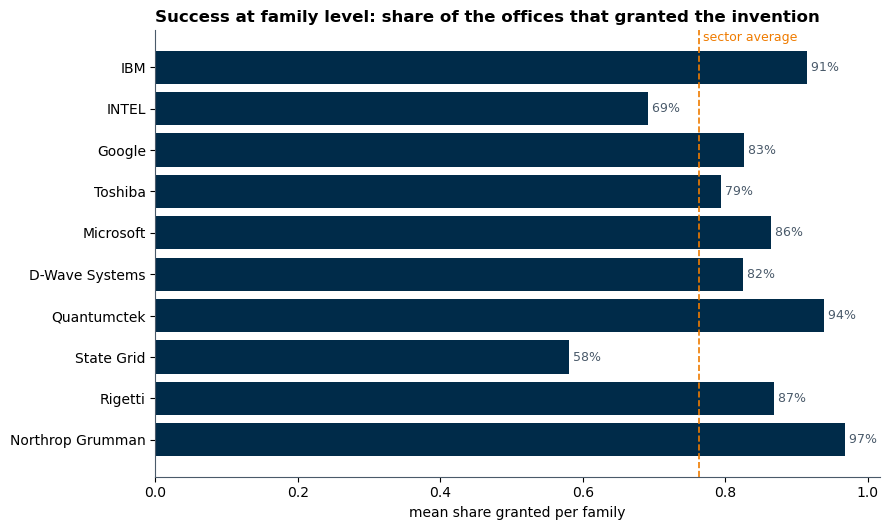

,6.1 global apps,6.2 family-level
firm,,
IBM,0.89,0.91
INTEL,0.56,0.69
Google,0.83,0.83
Toshiba,0.81,0.79
Microsoft,0.86,0.86
D-Wave Systems,0.83,0.82
Quantumctek,0.91,0.94
State Grid,0.59,0.58
Rigetti,0.82,0.87


In [24]:
families["family_success"] = families.docdb_family_id.map(
    national.groupby("docdb_family_id").granted.apply(lambda s: (s == "Y").mean())
)
family_success = per_firm("family_success")

# Plot family-level success across offices (Refinement)
firm_bars(
    family_success, 
    "Success at family level: share of the offices that granted the invention",
    "mean share granted per family", 
    fmt="{:.0%}", 
    ref=families.family_success.mean(), 
    ref_label="sector average"
)

pd.concat([success_global, family_success], axis=1) \
  .rename(columns={"success_global": "6.1 global apps", "family_success": "6.2 family-level"}) \
  .rename(index=SHORT) \
  .round(2)

**Reading it.** The family-level success is close to 6.1 for most firms (differences up to 5 points), and the order of the top does not change: Northrop Grumman (97%), QuantumCTek (94%), IBM (91%), Rigetti (87%) and Microsoft (86%). The exception is Intel, which gains 13 points (56% to 69%): its refused or pending applications are concentrated in a few families, so counting each invention once makes it look better. State Grid stays at the bottom in both (59% and 58%). Success is the indicator that separates the firms the least (the coefficient of variation is computed in 8.1): small differences are noise.

**Reading the two columns together**

- **High in both**: The firm's innovations achieve are accepted both at the individual application level and across its patent families.
- **High in 6.1, Low in 6.2**: The firm shows a high application grant rate, but a lower average success rate when evaluated invention-by-invention (family level). 
- **Low in 6.1, High in 6.2**: The firm has a high average success rate per family, but a lower aggregate application success rate. 

### 6.3 Refinement: Grant Lag and Examination

The duration of the examination process measures the time elapsed from the initial filing date to the final grant of the patent. 
A hard-fought examination means the claims were rigorously tested against the prior art; a long lag also signals complex and uncertain technologies. Conversely, straightforward or incremental innovations may pass through the office much faster. The length of time an examiner spends evaluating an application serves as an interesting proxy for firm success:

$$\text{Grant Lag}_p = \text{Grant Date}_p - \text{Filing Date}_p$$

We compute the average grant lag across a firm’s granted patents to evaluate the complexity associated with its portfolio

* **Watch out:** Applicants can sometimes slow down the examination on purpose to keep their claims open while the market evolves.

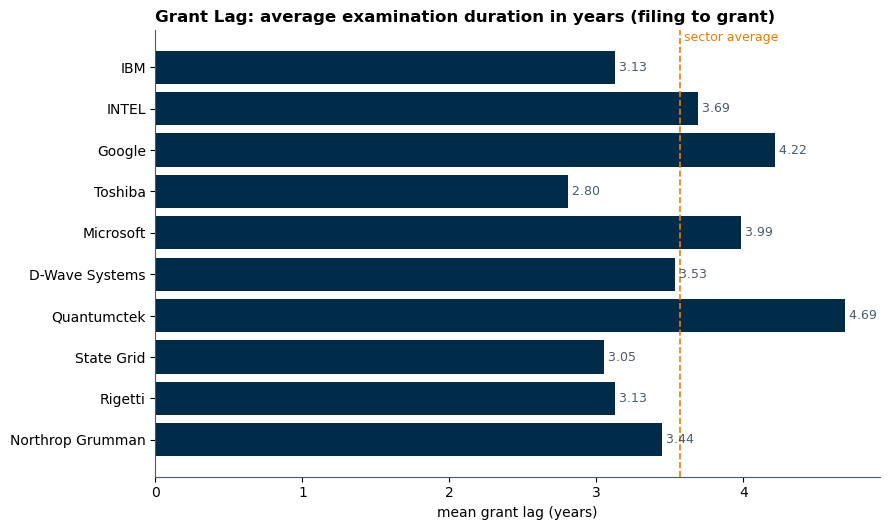

In [25]:
q_lag = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_filing_date,
        TLS211_PAT_PUBLN.publn_date,
        TLS201_APPLN.granted
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.granted == "Y")
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    .filter(TLS211_PAT_PUBLN.publn_first_grant == "Y")
)
lag_df = patstat.df(q_lag).drop_duplicates("appln_id")

lag_df["appln_filing_date"] = pd.to_datetime(lag_df["appln_filing_date"], errors="coerce")
lag_df["publn_date"] = pd.to_datetime(lag_df["publn_date"], errors="coerce")
lag_df["grant_lag_years"] = (lag_df["publn_date"] - lag_df["appln_filing_date"]).dt.days / 365.25

valid_lag = lag_df[(lag_df["grant_lag_years"] >= 0) & (lag_df["grant_lag_years"] <= 20)]

family_lag = valid_lag.groupby("docdb_family_id")["grant_lag_years"].mean()
families["family_lag"] = families.docdb_family_id.map(family_lag)

lag_firm = per_firm("family_lag").rename("grant_lag")

firm_bars(
    lag_firm, 
    "Grant Lag: average examination duration in years (filing to grant)", 
    "mean grant lag (years)", 
    ref=lag_firm.mean(), 
    ref_label="sector average"
)

**Reading it.** The average time from filing to grant goes from 2.8 years for Toshiba to 4.7 for QuantumCTek (State Grid 3.1, IBM and Rigetti 3.1, Northrop Grumman 3.4, D-Wave 3.5, Intel 3.7, Microsoft 4.0, Google 4.2). The lag depends on the speed of each office, so it partly reflects where the firm files. Moreover, it can be read in two directions (a long examination means that the claims were tested, but important patents may also be granted fast), and applicants can slow it on purpose.

### 6.4 Refinement: Number of Claims (Legal Scope)

The **number of claims** in a patent sets its legal boundary of protection. More claims generally mean a broader legal scope, offering multiple fallback positions and more ways to block imitators in the market. 

While applicants often try to balance breadth with clarity, a rich claim structure signals a well-protected invention and a strong strategic effort to secure commercial exclusivity across various facets of the technology.
* **Watch out:** Some applicants inflate claims for strategic reasons.

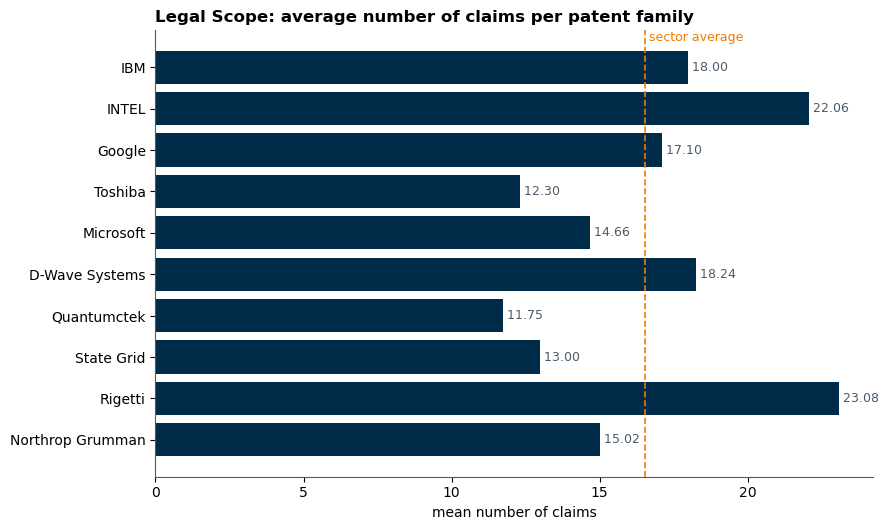

,6.1 global apps,6.2 family-level,6.3 grant lag (yrs),6.4 claims scope
firm,,,,
IBM,0.89,0.91,3.13,18.00
INTEL,0.56,0.69,3.69,22.06
Google,0.83,0.83,4.22,17.10
Toshiba,0.81,0.79,2.80,12.30
Microsoft,0.86,0.86,3.99,14.66
D-Wave Systems,0.83,0.82,3.53,18.24
Quantumctek,0.91,0.94,4.69,11.75
State Grid,0.59,0.58,3.05,13.00
Rigetti,0.82,0.87,3.13,23.08


In [26]:
q_claims = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS211_PAT_PUBLN.publn_claims
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
claims_df = patstat.df(q_claims).drop_duplicates("appln_id")

claims_df["publn_claims"] = pd.to_numeric(claims_df["publn_claims"], errors="coerce").fillna(0)

family_claims = claims_df[claims_df["publn_claims"] > 0].groupby("docdb_family_id")["publn_claims"].mean()
families["family_claims"] = families.docdb_family_id.map(family_claims)

claims_firm = per_firm("family_claims").rename("number_of_claims")

firm_bars(
    claims_firm, 
    "Legal Scope: average number of claims per patent family", 
    "mean number of claims", 
    ref=claims_firm.mean(), 
    ref_label="sector average"
)

pd.concat([success_global, family_success, lag_firm, claims_firm], axis=1) \
  .rename(columns={
      "success_global": "6.1 global apps", 
      "family_success": "6.2 family-level",
      "grant_lag": "6.3 grant lag (yrs)",
      "number_of_claims": "6.4 claims scope"
  }) \
  .rename(index=SHORT) \
  .round(2)

**Reading it.** The number of claims per family is highest for Rigetti (23.1), Intel (22.1), D-Wave (18.2) and IBM (18.0), and lowest for QuantumCTek (11.8), Toshiba (12.3) and State Grid (13.0). The pattern follows the home market: US-first filers write more claims, Japanese and Chinese ones fewer. The conventions of the offices (for example the fees per claim in the US) weigh as much as the strategy, so we do not use it as a measure of quality.

**Success in short** It is the dimension that separates the firms least: eight firms are between 81% and 97%, and only Intel (56%) and State Grid (59%) are clearly lower. We expect it to move the final ranking less than the other dimensions.

## 7. Globalization: breadth of market protection

Protecting the same invention in many countries is expensive (attorneys, translations, fees at every office and then renewals every year), so a firm extends a family abroad only when it expects the invention to be worth it on those markets (lecture, *Family size*). For our client this is also a very concrete question: a patent protects only where it is in force, so a portfolio filed only at home is worth little on the markets where Dell actually sells servers and storage.

In our sector we expect this dimension to separate the firms a lot. In Step 1 we found 1.89 applications per family in 2022 against 1.47 for patenting as a whole, but also that the quantum communication block is full of single-office filings at CNIPA (`docs/appropriability.md`). So we expect two groups: firms that file worldwide and firms that file only in their home market.

### 7.1 Basics: offices per family

For each family we count the distinct offices (`appln_auth`) of its applications, at any office:

- we use the same `national` applications of section 6: no `WO` (a PCT request is not protection anywhere yet) and no kind `T` (translations of granted EP patents: they are the EP patent validated in a country, and refinement 7.2 counts them properly);
- `EP` counts as **one** office here; refinement 7.2 opens it up into states;
- a family with a PCT request and no national application yet counts as 1 office, as in the tutorial.

$$\text{Globalization}_f=\text{mean number of distinct offices per family of firm } f$$

Share of the sector's families filed at each office (the 10 most frequent):
appln_auth
CN    52.0%
US    51.5%
EP    20.5%
JP    16.6%
KR    10.9%
CA     7.4%
AU     4.8%
GB     4.5%
DE     2.5%
ES     2.1%


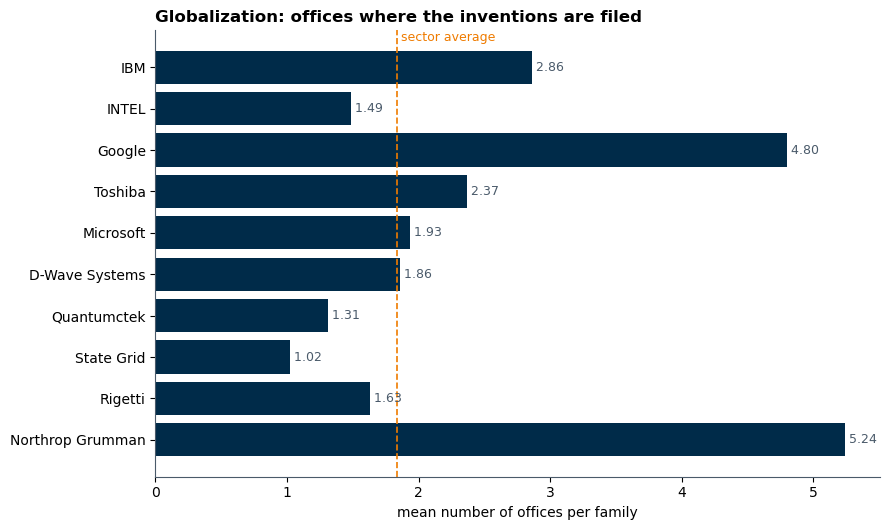

In [27]:
families["offices"] = families.docdb_family_id.map(national.groupby("docdb_family_id").appln_auth.nunique()).fillna(1)
globalization = per_firm("offices").rename("globalization")

reach = national.drop_duplicates(["docdb_family_id", "appln_auth"]).appln_auth.value_counts() / len(families)
print("Share of the sector's families filed at each office (the 10 most frequent):")
print((reach.head(10) * 100).round(1).astype(str).add("%").to_string())

firm_bars(globalization, "Globalization: offices where the inventions are filed",
          "mean number of offices per family", ref=families.offices.mean(), ref_label="sector average")

A mean can hide very different shapes: a firm with half of its families at one office and half at eight offices has the same mean (4.5) as a firm with every family at four or five offices. So next to the mean we look at the median and at the share of families filed at **one office only**, the families that the firm decided not to protect abroad at all.

In [28]:
families["single_office"] = (families.offices == 1).astype(int)
pd.concat([globalization.rename("mean offices"),
           per_firm("offices", "median").rename("median offices"),
           per_firm("single_office").rename("share at one office only")], axis=1).rename(index=SHORT).round(2)

,mean offices,median offices,share at one office only
firm,,,
IBM,2.86,3.0,0.44
INTEL,1.49,1.0,0.76
Google,4.80,5.0,0.08
Toshiba,2.37,2.0,0.12
Microsoft,1.93,2.0,0.43
D-Wave Systems,1.86,1.0,0.62
Quantumctek,1.31,1.0,0.86
State Grid,1.02,1.0,0.98
Rigetti,1.63,1.0,0.63


**What we see.** The average family of the window is filed at 1.8 offices, and 69% of the families are filed at **one office only**: most quantum inventions are protected in one country. CNIPA and the USPTO dominate (52% of the families each), the EPO comes far behind (21%), then Japan (17%) and Korea (11%).

The scored firms split into three groups:

- **worldwide filers**: Northrop Grumman (5.2 offices per family, only 10% of its families at one office) and Google (4.8, 8%): nearly every invention is protected in several markets;
- **US-first filers**: IBM (2.9), Microsoft (1.9), D-Wave (1.9), Rigetti (1.6) and above all Intel (1.5, with 76% of its families at one office). They file almost everything at the USPTO and go abroad only for a selection;
- **domestic filers**: QuantumCTek (1.3, 86% at one office) and State Grid (1.0, 98%): almost the whole portfolio is protected only in China.

IBM is an interesting case: 44% of its families stay at one office, but its median is 3 offices, so it extends widely the inventions it cares about and leaves the rest in the US. Toshiba (2.4) almost never files at one office only (12%): it files in Japan and in the US systematically, and rarely beyond.

### 7.2 Refinement: in which European states are the EP patents validated?

A granted EP patent is not yet protection anywhere: the owner must **validate** it in each state where it wants protection (translations, fees), and then pay a **renewal** fee every year in each of them. The number of states is a strong signal of how much the owner values the patent, because each state costs money every year.

PATSTAT has this in the **legal events** (`TLS231`), not in `TLS201`. Three event codes describe the life of an EP patent in each state:

| Code | Meaning | Country in |
|---|---|---|
| `PGFP` | annual fee paid to a national office: the patent is (or was) valid there | `fee_country` |
| `VSFP` | annual fee paid to a **validation state** outside the EPC (e.g. Morocco) | `fee_country` |
| `PG25` | patent **lapsed** in a state, with the reason in `lapse_text` | `lapse_country` |

As in the tutorial, a `PG25` counts as validated only if the reason is *non-payment of due fees* (the patent was valid, then the owner stopped paying); a lapse for *failure to submit a translation* means the owner never validated it there.

**Difference with the tutorial.** There every family had an EP application, because the sample was built at the EPO. Our sector is built at **all** offices, so this refinement only reads the families that went to Europe and got the grant. Before using it we print how many they are: if only a small part of a firm's portfolio has a granted EP patent, its number of states describes a few families, not the firm.

In [29]:
ep = members[members.appln_auth == "EP"].copy()
ep_granted = [int(i) for i in ep.loc[ep.granted == "Y", "appln_id"]]
print(f"Families with an EP application: {ep.docdb_family_id.nunique():,} of {len(families):,} "
      f"({ep.docdb_family_id.nunique() / len(families):.0%}); granted EP applications: {len(ep_granted):,}")

q = (
    db.query(TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS231_INPADOC_LEGAL_EVENT.event_code,
             TLS231_INPADOC_LEGAL_EVENT.fee_country, TLS231_INPADOC_LEGAL_EVENT.lapse_country,
             TLS231_INPADOC_LEGAL_EVENT.lapse_text)
    .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(ep_granted))
    .filter(TLS231_INPADOC_LEGAL_EVENT.event_code.in_(["PGFP", "VSFP", "PG25"]))
)
events_val = patstat.df(q)
events_val["lapse_text"] = events_val.lapse_text.fillna("").str.upper()
print("\nEvents by code:", events_val.event_code.value_counts().to_dict())
print("\nReasons of the PG25 lapses:")
print(events_val[events_val.event_code == "PG25"].lapse_text.str[:70].value_counts().head(5).to_string())

# validated = fee paid (PGFP, VSFP), or lapsed for non-payment after being valid (PG25 + NON-PAYMENT)
lapsed_after_valid = (events_val.event_code == "PG25") & events_val.lapse_text.str.contains("NON-PAYMENT")
val = events_val[events_val.event_code.isin(["PGFP", "VSFP"]) | lapsed_after_valid].copy()
val["country"] = np.where(val.event_code == "PG25", val.lapse_country, val.fee_country)
val["country"] = val.country.fillna("").str.strip()
val = val[(val.country != "") & (val.country != "EP")].drop_duplicates(["appln_id", "country"])

Families with an EP application: 629 of 3,061 (21%); granted EP applications: 485



Events by code: {'PG25': 14944, 'PGFP': 1643}

Reasons of the PG25 lapses:
lapse_text
LAPSE BECAUSE OF FAILURE TO SUBMIT A TRANSLATION OF THE DESCRIPTION OR    12905
LAPSE BECAUSE OF NON-PAYMENT OF DUE FEES                                   2039


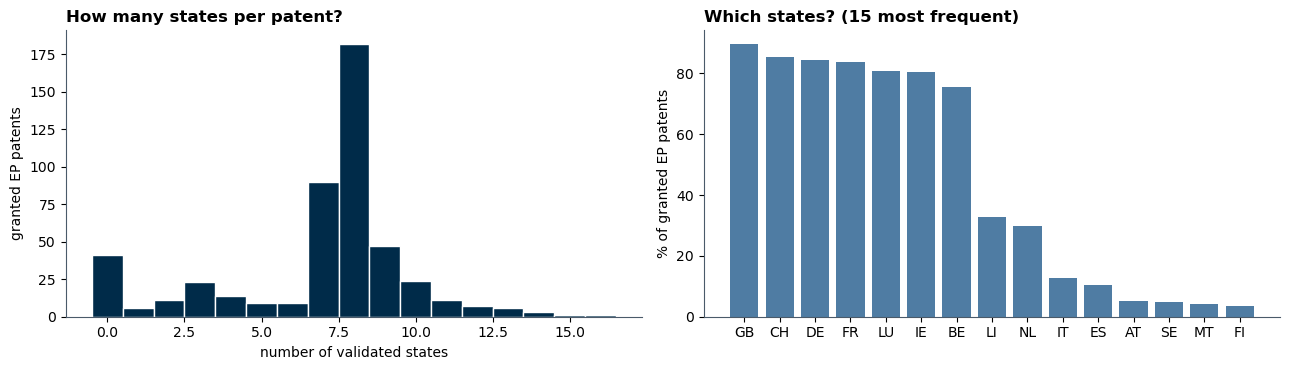

Granted EP patents with no validation event: 8%; median number of states: 8


In [30]:
states = val.groupby("appln_id").country.nunique()
n_states = pd.Series(ep_granted).map(states).fillna(0)          # granted patents with no event: 0 states
country_share = val.country.value_counts() / len(ep_granted)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(n_states, bins=range(0, int(n_states.max()) + 2), color=NAVY, edgecolor="white", align="left")
axes[0].set_xlabel("number of validated states")
axes[0].set_ylabel("granted EP patents")
axes[0].set_title("How many states per patent?")
top_states = country_share.head(15)
axes[1].bar(top_states.index, top_states.values * 100, color=BLUE)
axes[1].set_ylabel("% of granted EP patents")
axes[1].set_title("Which states? (15 most frequent)")
plt.tight_layout()
plt.show()
print(f"Granted EP patents with no validation event: {(n_states == 0).mean():.0%}; "
      f"median number of states: {n_states.median():.0f}")

**A pattern worth noticing.** The median granted EP patent of our sector is validated in 8 states, and the most frequent states are GB, CH, DE, FR, LU, IE and BE (76% to 90% of the patents). These are almost exactly the states that, under the **London Agreement**, ask for no translation of a patent granted in English, French or German: there validation costs only the fees. Beyond them (the Netherlands 30%, Italy 13%) the owner has to pay for translations, and few do. So in our sector the number of states mainly tells us whether the owner went **beyond this cheap core**, which is a rarer and stronger signal than the raw number suggests.

The indicator for a firm is the mean number of validated states of its **granted** EP families (a family takes its best EP patent). Next to it we print how many of the firm's families have a granted EP patent at all, which tells us how much of the portfolio the number describes.

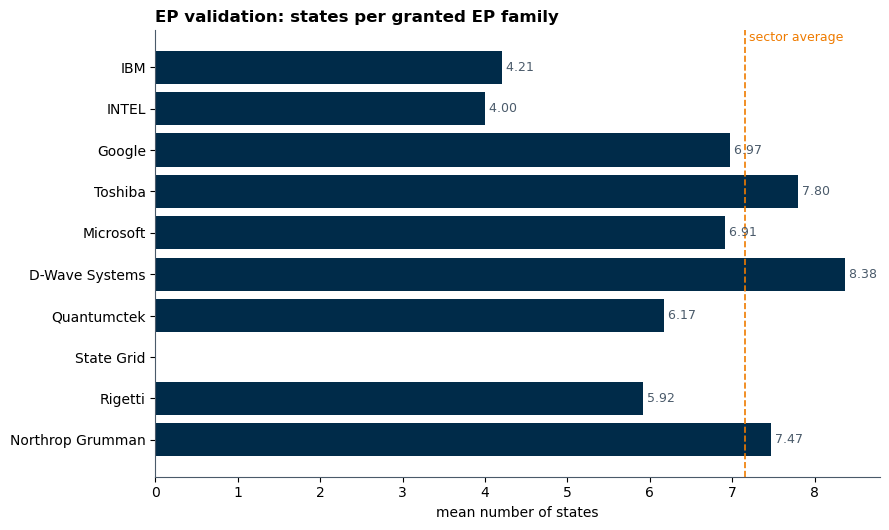

,families with a granted EP,share of the firm's families,mean states
firm,,,
IBM,24,0.16,4.21
INTEL,2,0.02,4.00
Google,65,0.76,6.97
Toshiba,5,0.06,7.80
Microsoft,33,0.43,6.91
D-Wave Systems,8,0.11,8.38
Quantumctek,6,0.09,6.17
State Grid,0,0.00,NaN
Rigetti,13,0.27,5.92


In [31]:
ep_g = ep[ep.granted == "Y"].copy()
ep_g["states"] = ep_g.appln_id.map(states).fillna(0)
families["ep_states"] = families.docdb_family_id.map(ep_g.groupby("docdb_family_id").states.max())
families["ep_granted"] = families.docdb_family_id.isin(ep_g.docdb_family_id).astype(int)
ep_states = per_firm("ep_states")
ep_reach = per_firm("ep_granted").rename("granted_ep_share")

firm_bars(ep_states, "EP validation: states per granted EP family", "mean number of states",
          ref=families.ep_states.mean(), ref_label="sector average")
pd.concat([per_firm("ep_granted", "sum").rename("families with a granted EP"),
           ep_reach.rename("share of the firm's families"), ep_states.rename("mean states")],
          axis=1).rename(index=SHORT).round(2)

**Reading it.** Only 14% of the families of the window have a granted EP patent, so this refinement describes a small part of the sector. It is meaningful for Northrop Grumman (78% of its families), Google (76%) and Microsoft (43%); for Intel (2 families), Toshiba (5), QuantumCTek (6) and State Grid (none) the mean rests on a handful of patents and we do not read it. Among the firms with enough granted EP patents, Northrop Grumman (7.5 states), Google and Microsoft (about 7) go beyond the core, while IBM (4.2 states on 24 families) mostly keeps a few large markets.

### 7.3 Refinement: quadrilateral families, the Clarivate measure

Counting offices treats every office the same: Australia counts as much as the United States. Clarivate looks instead at the **four main markets**, the offices of China (CN), Europe (EP), Japan (JP) and the United States (US). A **quadrilateral family** is filed at all four: an expensive choice, made only for inventions with a global market.

$$\text{Quadrilateral share}_f=\frac{\text{families of } f \text{ filed at CN, EP, JP and US}}{\text{families of } f}$$

Two differences with the tutorial. First, our families do not all have an EP application, so a family must reach **all four** offices, EP included. Second, being 0/1 the quadrilateral share is harsh: a family filed at US, EP and CN but not JP counts as 0, like a family filed only in China. So we also compute a softer version on the **IP5 offices** we already used in Step 1 (CN, EP, JP, KR, US, from `sector.yaml`): the mean number of IP5 offices reached per family, from 0 to 5.

Quadrilateral families in the sector: 7%; mean IP5 offices per family: 1.52


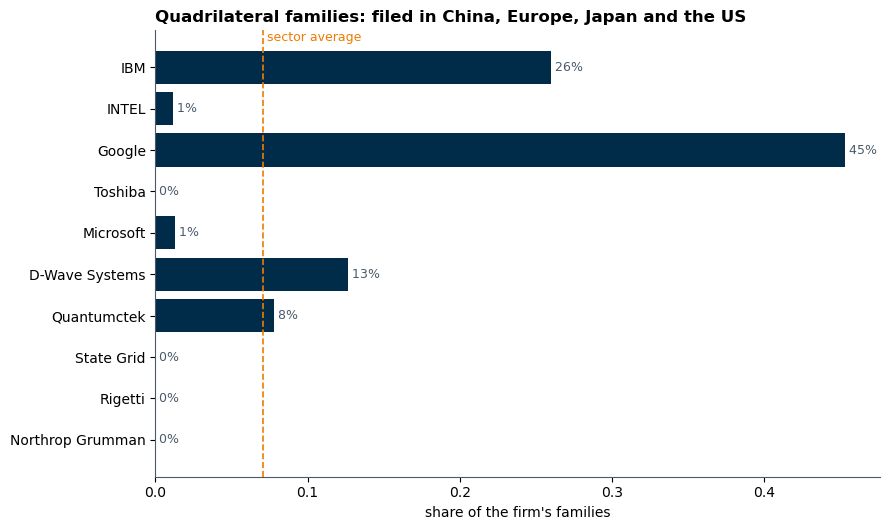

,quadrilateral_share,ip5_offices
firm,,
IBM,0.26,2.33
INTEL,0.01,1.07
Google,0.45,3.28
Toshiba,0.00,1.90
Microsoft,0.01,1.87
D-Wave Systems,0.13,1.75
Quantumctek,0.08,1.30
State Grid,0.00,1.02
Rigetti,0.00,1.41


In [32]:
QUAD = {"CN", "EP", "JP", "US"}
IP5 = set(cfg.ip5_offices)                      # CN, EP, JP, KR, US

offices_of = national.groupby("docdb_family_id").appln_auth.agg(set)
families["quadrilateral"] = families.docdb_family_id.map(lambda f: QUAD <= offices_of.get(f, set())).astype(int)
families["ip5_offices"] = families.docdb_family_id.map(lambda f: len(IP5 & offices_of.get(f, set())))
quadrilateral_share = per_firm("quadrilateral").rename("quadrilateral_share")
ip5_reach = per_firm("ip5_offices").rename("ip5_offices")

print(f"Quadrilateral families in the sector: {families.quadrilateral.mean():.0%}; "
      f"mean IP5 offices per family: {families.ip5_offices.mean():.2f}")
firm_bars(quadrilateral_share, "Quadrilateral families: filed in China, Europe, Japan and the US",
          "share of the firm's families", fmt="{:.0%}", ref=families.quadrilateral.mean(), ref_label="sector average")
pd.concat([quadrilateral_share, ip5_reach], axis=1).rename(index=SHORT).round(2)

**Reading it.** Only 7% of the sector's families are quadrilateral (217 of 3,061), against 47% in the coffee-capsule example of the tutorial: in quantum computing the four main markets together are rare, because few families go to the EPO and the JPO. Google and IBM hold 39 of these families each, more than a third of the total between them.

The surprise is **Northrop Grumman**: the firm with the most offices per family (5.2) has **0% quadrilateral families**. The reason is one office. It files in the US (100% of its families), in Europe and Japan (90%), Canada (88%), Australia (85%) and Korea (71%), but **never in China**. For a US defence contractor this is very likely a deliberate choice (export controls on quantum technologies, and no wish to disclose to a strategic competitor) rather than a sign of low value. It shows the limit of the Clarivate measure in our sector: a family can be truly global without China, and a 0/1 indicator cannot see it. The softer IP5 count does: Northrop Grumman reaches 3.5 IP5 offices per family, the highest of all, ahead of Google (3.3).

### 7.4 Refinement: protection outside the home market

Every count above includes the **home office**, which is the cheapest and the most obvious one: a Chinese firm filing at CNIPA or an American firm filing at the USPTO is not yet "going global". What really costs, and what really signals value, is the decision to protect the invention **abroad**. This matters in our sector because the top players of section 3 mix US and Japanese multinationals with Chinese applicants (QuantumCTek and State Grid in our window, Origin Quantum over the whole period), and Step 1 already suggested that a good part of the Chinese activity is filed only at CNIPA.

For each (family, firm) pair, the family is protected abroad if it has at least one national application at an office outside the firm's **home market**:

- the home country is the `ctry` given to the applicant by the harmonisation of Step 2 (`prepare_applicants`, the most frequent country of the applicant);
- for a firm of an EPC member state, the EPO is also home: a German firm filing at DE and EP has not left Europe.

$$\text{Foreign reach}_f=\frac{\text{families of } f \text{ filed at least at one office outside its home market}}{\text{families of } f}$$

It is computed per (family, firm) and not per family, because a co-owned family can be "home" for one owner and "abroad" for the other.

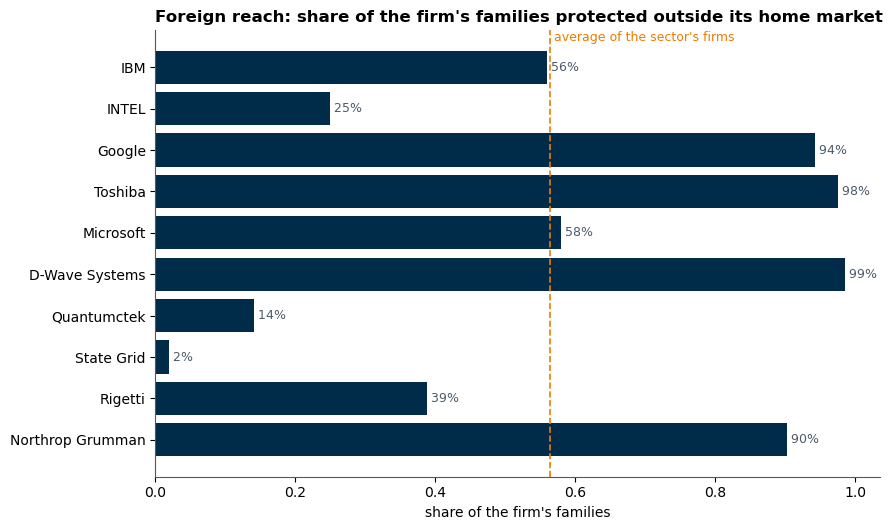

,home,foreign_share
firm,,
IBM,US,0.56
INTEL,US,0.25
Google,US,0.94
Toshiba,JP,0.98
Microsoft,US,0.58
D-Wave Systems,CA,0.99
Quantumctek,CN,0.14
State Grid,CN,0.02
Rigetti,US,0.39


In [33]:
EPC_STATES = {"AL", "AT", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GB", "GR", "HR",
              "HU", "IE", "IS", "IT", "LI", "LT", "LU", "LV", "MC", "ME", "MK", "MT", "NL", "NO", "PL", "PT",
              "RO", "RS", "SE", "SI", "SK", "SM", "TR"}


def home_offices(ctry):
    "The offices that count as the home market of an applicant of country ctry."
    return {ctry, "EP"} if ctry in EPC_STATES else {ctry}


firm_home = fam_firm.dropna(subset=["ctry"]).groupby("firm").ctry.agg(lambda c: c.mode().iat[0])
abroad = fam_firm[["docdb_family_id", "firm"]].copy()
abroad["home"] = abroad.firm.map(firm_home)
abroad = abroad.dropna(subset=["home"])
abroad["abroad"] = [int(len(offices_of.get(f, set()) - home_offices(h)) > 0)
                    for f, h in zip(abroad.docdb_family_id, abroad.home)]
foreign_share = abroad.groupby("firm").abroad.mean().reindex(TOP).rename("foreign_share")

firm_bars(foreign_share, "Foreign reach: share of the firm's families protected outside its home market",
          "share of the firm's families", fmt="{:.0%}", ref=abroad.abroad.mean(),
          ref_label="average of the sector's firms")
pd.concat([firm_home.reindex(TOP).rename("home"), foreign_share], axis=1).rename(index=SHORT).round(2)

**Reading it.** Foreign reach makes the split of 7.1 sharper: State Grid protects 2% of its families outside China, QuantumCTek 14%. At the other end Toshiba (98%), D-Wave (99%), Google (94%) and Northrop Grumman (90%) protect almost everything abroad.

But the measure has a bias that we must say clearly: **it depends on the home market**. For D-Wave (Canada) and Toshiba (Japan), "abroad" means first of all the USPTO, where any firm selling in the US files anyway: D-Wave files 99% of its families in the US and only 6% in Canada. For a US firm the largest market is already home, and going abroad is a real extra cost. So the same foreign reach does not mean the same effort for a US and a non-US firm, and this is why the basic indicator stays the number of offices of 7.1.

**Globalization in short.** The four measures agree on the bottom (State Grid, QuantumCTek, Intel) and on the top (Google, Northrop Grumman), and disagree in the middle depending on what we count: offices, the four big markets, or leaving the home market. For Dell the key fact is that the Chinese firms of our list are protected almost only in China, while Google and IBM hold most of the families protected in all four main markets.

## 8. From four indicators to one ranking

Each firm now has four basic numbers. To rank the firms we need **one** number per firm, and as in the tutorial we get there in three steps:

1. **make the indicators comparable**, because they are in different units;
2. **choose the weights**: how much each dimension counts for our sector and for Dell's question;
3. **combine** them into one score, and sort.

The starting point is the indicator table: one row per firm, one column per basic indicator. For success the basic indicator is the one of 6.1, the share of **global** applications granted (we decided in section 6 not to restrict it to the EPO, because many firms of our sector do not file there). All the refinements go in a second table, `extras`, used in section 10.

In [34]:
INDICATORS = ["volume", "influence", "success", "globalization"]
success = success_global.rename("success")          # basic success of 6.1: global applications

firms = pd.concat([n_families.reindex(TOP).rename("families"), volume, influence, success, globalization], axis=1)
extras = pd.concat([volume_change, recent_momentum,
                    by_window.rename(columns=lambda c: "influence_" + c.split()[0] + "y"),
                    applicant_share, blocking_share, blocking_power, back_firm, sci_firm, orig_firm, gen_firm,
                    family_success, lag_firm, claims_firm,
                    ep_states, ep_reach, quadrilateral_share, ip5_reach, foreign_share], axis=1)
firms.rename(index=SHORT).round(3)

,families,volume,influence,success,globalization
firm,,,,,
IBM,150,0.049,1.575,0.893,2.860
INTEL,88,0.029,2.696,0.558,1.489
Google,86,0.028,1.657,0.826,4.802
Toshiba,81,0.026,0.796,0.808,2.370
Microsoft,76,0.025,1.360,0.864,1.934
D-Wave Systems,71,0.023,2.296,0.833,1.859
Quantumctek,64,0.021,0.506,0.912,1.312
State Grid,50,0.016,0.568,0.588,1.020
Rigetti,49,0.016,3.583,0.822,1.633


### 8.1 Before combining: how much does each indicator tell us?

Before choosing a method and the weights we check two things on the four columns, as suggested by the OECD-JRC *Handbook on Constructing Composite Indicators* (2008) before any aggregation:

- **how much each indicator separates the firms**. The coefficient of variation (standard deviation ÷ mean) says it in one number: an indicator on which all firms are almost equal cannot move the ranking much, whatever weight we give it. The ratio *max ÷ mean* tells if one firm is far ahead of the others, which is the warning of the tutorial for the ratio to the mean (8.3);
- **whether two indicators measure the same thing**. If two of them were correlated close to 1 we would be counting the same dimension twice; a negative correlation is a trade-off between dimensions (for example big portfolios that are less cited on average).

With ten firms a correlation is very noisy (one firm can move it a lot), so we read only the large values.

In [35]:
diagnostics = pd.DataFrame({
    "min": firms[INDICATORS].min(),
    "max": firms[INDICATORS].max(),
    "max / mean": firms[INDICATORS].max() / firms[INDICATORS].mean(),
    "coef. of variation": firms[INDICATORS].std() / firms[INDICATORS].mean(),
})
display(diagnostics.round(2))
firms[INDICATORS].corr(method="spearman").round(2)

,min,max,max / mean,coef. of variation
volume,0.01,0.05,1.98,0.41
influence,0.51,3.58,2.16,0.59
success,0.56,0.97,1.20,0.16
globalization,1.02,5.24,2.14,0.59


,volume,influence,success,globalization
volume,1.00,0.18,-0.25,0.19
influence,0.18,1.00,-0.27,0.18
success,-0.25,-0.27,1.00,0.47
globalization,0.19,0.18,0.47,1.00


**Reading it.**

- **Success separates the firms much less than the others**: coefficient of variation 0.16, against 0.41 to 0.59 for the other three. Eight of the ten firms have a grant rate between 0.81 and 0.97; only Intel (0.56) and State Grid (0.59) are clearly apart. Whatever its weight, success moves the ranking less than the other dimensions, and differences of a few points are noise more than quality.
- **Volume, influence and globalization are skewed**: in each of them one firm is about twice the average (IBM on volume, Rigetti on influence, Northrop Grumman on globalization), right at the limit of the tutorial's warning for the ratio to the mean.
- **No two indicators measure the same thing**: the largest correlation is 0.47, between success and globalization (firms that file in many offices also see their applications granted more often, maybe because they extend only their best inventions). Volume is almost unrelated to influence (0.18): in our sector being big does not mean being cited, which is exactly why a score needs more than volume.

### 8.2 Step 1 · Make the indicators comparable: two solutions

| | **A · Ratio to the mean** | **B · Ranks** |
|---|---|---|
| How | divide each value by the average of the scored firms | on each indicator, sort the firms: 1st, 2nd, 3rd... |
| Reads as | "1.4 = 40% above the average firm" | "3rd of 10 on influence" |
| Keeps | the **size of the gaps** | only the **order** |

**A · Ratio to the mean.** The same idea as the normalisation of influence (5.1): there each family was compared with the average of its year, here each firm with the average firm. In the map blue is above the average firm, red below.

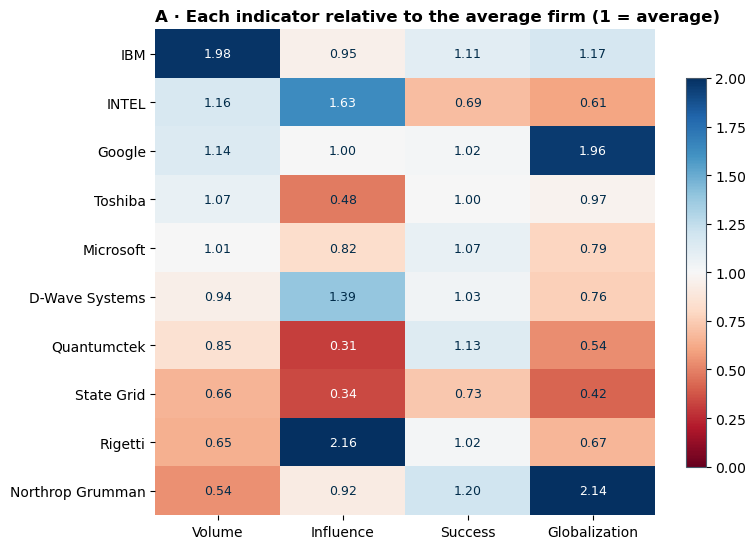

In [36]:
relative = firms[INDICATORS] / firms[INDICATORS].mean()              # A: 1 = average firm

fig, ax = plt.subplots(figsize=(8, 0.42 * len(relative) + 1.4))
im = ax.imshow(relative.values, cmap="RdBu", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS])
ax.set_yticks(range(len(relative)), [SHORT[f] for f in relative.index])
for i in range(relative.shape[0]):
    for j in range(relative.shape[1]):
        v = relative.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v - 1) > 0.6 else NAVY)
ax.spines[:].set_visible(False)
ax.set_title("A · Each indicator relative to the average firm (1 = average)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**B · Ranks.** On each indicator we give position 1 to the best firm, 2 to the second, and so on, and we draw them as a **leaderboard**: one column per indicator, the firms sorted from the 1st (top) to the last (bottom), and a thin line that follows each firm from one column to the next. A firm that stays near the top across the columns is strong everywhere; a line that zigzags is a firm strong on some dimensions and weak on others.

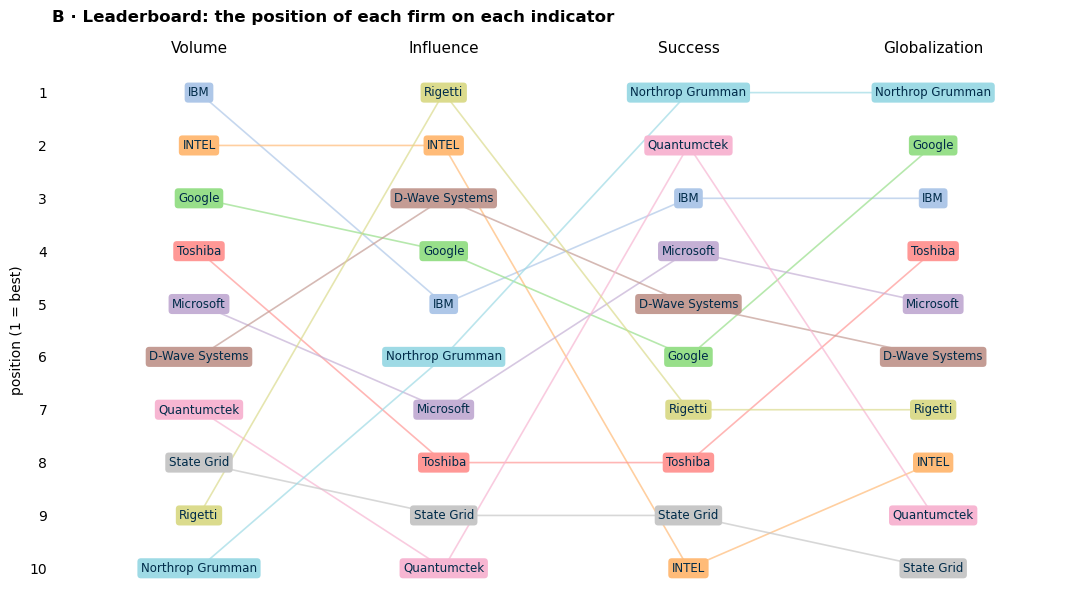

In [37]:
positions = firms[INDICATORS].rank(ascending=False, method="min")    # B: 1 = best firm on that indicator
shown = firms[INDICATORS].rank(ascending=False, method="first")       # same order, ties split only for the drawing

colour = {f: plt.cm.tab20(2 * k % 20 + 1) for k, f in enumerate(TOP)}
fig, ax = plt.subplots(figsize=(11, 0.5 * len(TOP) + 1.2))
for f in TOP:
    ax.plot(range(len(INDICATORS)), shown.loc[f, INDICATORS], color=colour[f], lw=1.2, alpha=0.7, zorder=1)
    for j, k in enumerate(INDICATORS):
        ax.text(j, shown.loc[f, k], SHORT[f], ha="center", va="center", fontsize=8.5, color=NAVY, zorder=2,
                bbox=dict(boxstyle="round,pad=0.3", fc=colour[f], ec="none"))
ax.set_xlim(-0.6, len(INDICATORS) - 0.4)
ax.set_ylim(len(TOP) + 0.6, 0.4)
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS], fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks(range(1, len(TOP) + 1))
ax.set_ylabel("position (1 = best)")
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_title("B · Leaderboard: the position of each firm on each indicator", pad=28)
plt.tight_layout()
plt.savefig(OUT / "fig_leaderboard.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the map and the leaderboard.** Almost no firm is strong everywhere:

- **IBM** is the only firm in the top 5 of all four indicators (1st in volume, 3rd in success and globalization, 5th in influence);
- **Google** and **Northrop Grumman** are the global filers. Northrop Grumman is 1st in success and in globalization but has the smallest portfolio of the ten (10th in volume);
- **Rigetti** and **Intel** are the influence leaders (1st and 2nd), but they protect their inventions in few offices, and Intel has the lowest grant rate of the list;
- **QuantumCTek** and **State Grid** are at the bottom of influence and globalization. QuantumCTek has one strong point, success (2nd): its Chinese applications are almost all granted.

### 8.3 Ratio to the mean or ranks? Our choice

The two solutions answer **different questions**: the ratio to the mean asks *how much* better a firm is, the ranks ask *where* a firm stands, whatever the size of the gaps.

For our ten firms the arguments point to **ranks**:

1. **Three of the four indicators are skewed** (8.1): in each of them one firm is about twice the average. With the mean, Rigetti's influence (2.2 times the average) alone gives it 76 points of score, almost twice what IBM gets from being the largest portfolio (40 points). Rigetti would end up 2nd overall while being 7th or worse on three dimensions out of four. And its influence is concentrated: its three most cited families make 20% of all its normalised citations, against 8% for IBM, so part of that lead comes from a few blockbuster patents (it also owns the family with the most X/I citations of the sector, 5.4).
2. **The question of the bank is a shortlist**: Dell wants to know who to approach first, which is a question about positions more than about distances.
3. **Our portfolios are small** (41 to 150 families): we trust the order of the firms more than the exact value of a ratio.

So we choose **B · RRF**. Its known cost is that tiny differences become full positions, and in our case this concerns success, where eight firms sit between 0.82 and 0.97. We accept it because success has a small weight (8.4) and because section 9 shows that dropping success changes almost nothing. The mean (A) and the geometric mean (C) stay in the notebook as checks.

### 8.4 Step 2 · Choose the weights

The weights $w_k$ say how much each dimension counts, and they sum to 1. There is no universal set: the tutorial puts electronics and telecom (thickets, cross-licensing: **volume** and **globalization**) on one side and software/AI (short-lived technology, many pending applications: **short citation windows**, volume over time) on the other. Quantum computing sits in between: it is hardware, but young and close to research. Our weights come from the sector, from the question of the bank and from the diagnostics of 8.1:

| Dimension | Weight | Why, for quantum computing and for Dell |
|---|---|---|
| **Influence** | **0.35** | The dominant design is not settled yet: superconducting, trapped-ion, photonic and spin qubits still compete. The firms whose patents the others build on are the ones most likely to own the architecture that wins, and for an acquirer this is the core of present value. Citations are also reliable here: 98% of our families have a complete 5-year window (5.2). |
| **Globalization** | **0.25** | Dell sells worldwide, and a patent protects only where it is in force: the value of a portfolio *for Dell* depends on its reach. Together with influence it is the dimension where our firms differ most (coefficient of variation 0.59, 8.1). |
| **Volume** | **0.20** | Size matters in an electronics-like sector (bargaining power in cross-licensing, defensive thickets), and it is the Clarivate gate. We keep it below influence because part of the volume in our window is built by domestic-only filing (QuantumCTek and State Grid, 7.4), and because volume is already used to **select** the firms (3.1). |
| **Success** | **0.20** | A granted patent passed an examination of novelty and inventive step, so it is a real quality signal. We do not give it more because the grant rate partly depends on *where* the firm files (offices differ a lot, 6.1) and because it separates our firms much less than the other three (coefficient of variation 0.16, 8.1). |

Equal weights (0.25 each) are also a choice: they would say that size counts as much as impact. We test them, and thousands of other sets, in section 9.

In [38]:
WEIGHTS = {"influence": 0.35, "globalization": 0.25, "volume": 0.20, "success": 0.20}
print("Sum of the weights:", round(sum(WEIGHTS.values()), 3))

Sum of the weights: 1.0


### 8.5 Step 3 · Combine

#### A · Weighted mean of the ratios

$$\text{Score}_f=100\cdot\sum_k w_k\cdot\frac{x_{f,k}}{\bar x_k}\qquad(100 = \text{average firm})$$

It is **compensatory**: a lot of one indicator makes up for little of another.

#### B · Reciprocal Rank Fusion (RRF) of the ranks

**Reciprocal Rank Fusion** (Cormack, Clarke and Büttcher, 2009) combines several rankings into one, as search engines do with the lists of different algorithms. Each indicator is one ranking; every position becomes points with $1/(c+\text{position})$ and the points are added with the weights:

$$\text{RRF}_f=100\cdot\sum_k w_k\cdot\frac{c+1}{c+\text{position}_{f,k}}\qquad(100 = \text{first on every indicator})$$

With 10 firms we use, as in the tutorial, $c$ = number of firms. The table shows how many points each position is worth (1st = 100):

In [39]:
RRF_C = len(TOP)                         # the constant c of RRF: the number of firms

pos = np.arange(1, len(TOP) + 1)
pd.DataFrame({"points": (100 * (RRF_C + 1) / (RRF_C + pos)).round(0).astype(int)},
             index=pd.Index(pos, name="position")).T

position,1,2,3,4,5,6,7,8,9,10
points,100,92,85,79,73,69,65,61,58,55


#### C · A third method only for the checks: the weighted geometric mean

The OECD-JRC Handbook suggests, next to the arithmetic mean, the **geometric** mean of the ratios:

$$\text{Geo}_f=100\cdot\prod_k\left(\frac{x_{f,k}}{\bar x_k}\right)^{w_k}\qquad(100 = \text{average firm on every indicator})$$

It sits between A and B: like A it keeps the size of the gaps, but it is only **partly compensatory**, because a very low value on one dimension pulls down the whole product (a firm at half the average on one indicator loses much more than it gains from being at 1.5 times the average on another). We do not use it for the final score, only in section 9 to see if the ranking depends on how compensatory the method is.

One function computes the three of them, so that sections 9 and 10 can reuse it:

In [40]:
def combine(table, weights, method):
    "One score per firm, higher = better. 'mean' and 'geo': 100 = average firm. 'rrf': 100 = first everywhere."
    w = pd.Series(weights, dtype=float)
    w = w / w.sum()
    t = table[w.index]
    if method == "mean":
        return 100 * (t / t.mean() * w).sum(axis=1)
    if method == "geo":
        ratio = (t / t.mean()).clip(lower=1e-3)                 # the product needs positive values
        return 100 * np.exp((np.log(ratio) * w).sum(axis=1))
    if method == "rrf":
        pos = t.rank(ascending=False, method="min")             # 1 = best on each indicator
        return 100 * (w * (RRF_C + 1) / (RRF_C + pos)).sum(axis=1)
    raise ValueError("method must be 'mean', 'geo' or 'rrf'")


def final_rank(scores):
    "From scores to the ranking: 1 = best firm."
    return scores.rank(ascending=False, method="min").astype(int)


both = pd.DataFrame({"A · mean": combine(firms, WEIGHTS, "mean"), "B · RRF": combine(firms, WEIGHTS, "rrf"),
                     "C · geo": combine(firms, WEIGHTS, "geo")})
for m in ["A · mean", "B · RRF", "C · geo"]:
    both[f"rank {m[0]}"] = final_rank(both[m])
positions.astype(int).add_prefix("pos. ").join(both.round(1)).sort_values("rank B").rename(index=SHORT)

,pos. volume,pos. influence,pos. success,pos. globalization,A · mean,B · RRF,C · geo,rank A,rank B,rank C
firm,,,,,,,,,,
IBM,1,5,3,3,124.2,83.7,119.5,3,1,2
Google,3,4,6,2,127.2,81.1,122.0,1,2,1
Northrop Grumman,10,6,1,1,120.5,80.1,107.8,4,3,4
INTEL,2,2,10,8,109.3,76.7,100.2,5,4,6
Rigetti,9,1,7,7,125.7,75.7,108.9,2,5,3
D-Wave Systems,6,3,5,6,106.9,75.2,104.0,6,6,5
Microsoft,5,7,4,5,90.0,71.4,89.3,7,7,7
Toshiba,4,8,8,4,82.4,69.0,77.8,8,8,8
Quantumctek,7,10,2,9,63.6,65.0,56.0,9,9,9


**How to read the table.** The first four columns are the positions on each indicator, then the three scores and their rankings. A firm with the same rank in A, B and C is placed the same way whatever the method: a solid result. A firm much higher in A than in B is far ahead on one indicator, and the mean rewards the size of that lead while RRF does not.

With the mean we can also show **what makes** each score: each indicator contributes $100\cdot w_k\cdot x_{f,k}/\bar x_k$.

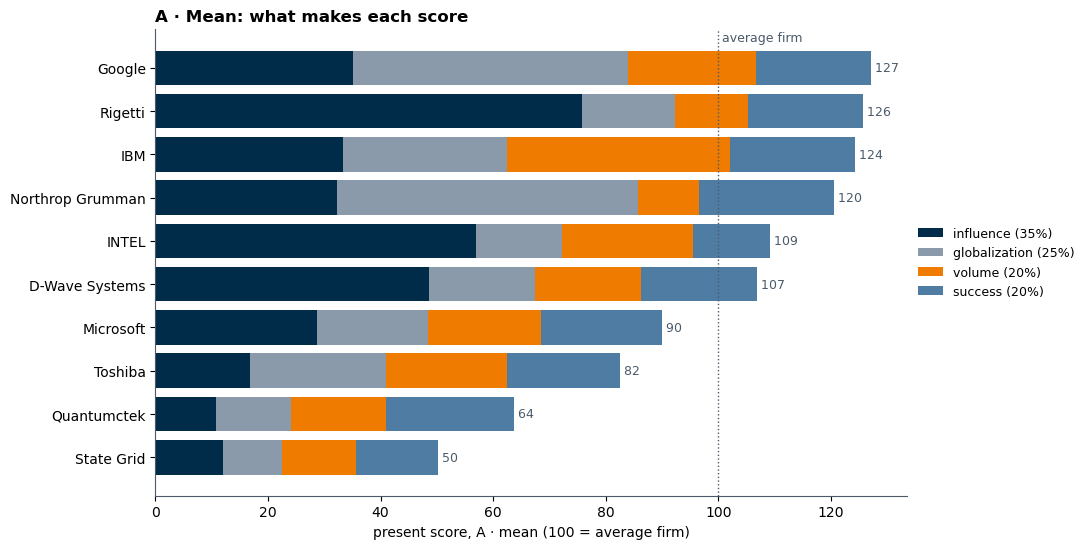

In [41]:
w = pd.Series(WEIGHTS)
contrib = 100 * relative[w.index] * w
order = combine(firms, WEIGHTS, "mean").sort_values().index

fig, ax = plt.subplots(figsize=(11, 0.42 * len(order) + 1.4))
left = np.zeros(len(order))
colours = {"influence": NAVY, "globalization": MID, "success": BLUE, "volume": ORANGE}
for k in w.index:
    vals = contrib.loc[order, k].values
    ax.barh([SHORT[f] for f in order], vals, left=left, color=colours[k], label=f"{k} ({w[k]:.0%})")
    left += vals
for y, x in enumerate(left):
    ax.text(x, y, f" {x:.0f}", va="center", fontsize=9, color=GREY)
ax.axvline(100, color=GREY, ls=":", lw=1)
ax.text(100, len(order) - 0.45, " average firm", color=GREY, fontsize=9, va="bottom")
ax.set_xlabel("present score, A · mean (100 = average firm)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_title("A · Mean: what makes each score")
plt.tight_layout()
plt.show()

**Reading the three methods.** They agree on the bottom of the ranking (Microsoft 7th, Toshiba 8th, QuantumCTek 9th, State Grid 10th in all three) and on the group at the top: IBM, Google and Northrop Grumman are in the first four whatever the method. They disagree on **Rigetti**: 2nd with the mean, 3rd with the geometric mean, 5th with RRF. The chart shows why: 76 of Rigetti's 126 points with the mean come from influence alone. This is the compensation discussed in 8.3, and the reason why the mean is not our method.

#### The final ranking

The method is set in `METHOD`; the reasons are in 8.3.

In [42]:
METHOD = "rrf"              # "mean" (A) or "rrf" (B)

firms["score"] = combine(firms, WEIGHTS, METHOD)
firms["rank"] = final_rank(firms.score)
firms.sort_values("rank")[["families", "score", "rank"]].round(1).rename(index=SHORT)

,families,score,rank
firm,,,
IBM,150,83.7,1
Google,86,81.1,2
Northrop Grumman,41,80.1,3
INTEL,88,76.7,4
Rigetti,49,75.7,5
D-Wave Systems,71,75.2,6
Microsoft,76,71.4,7
Toshiba,81,69.0,8
Quantumctek,64,65.0,9


## 9. Is the ranking robust?

Our ranking rests on three kinds of assumptions, and a ranking that changes completely when they change a little tells us little. We test them one at a time:

| | What we change | Section |
|---|---|---|
| **the method** | mean, RRF, geometric mean | 8.5 (table above) |
| **the weights** | a few sets chosen by hand, then thousands of random sets | 9.1, 9.2 |
| **the data** | the families of each firm, resampled | 9.3 |

### 9.1 A few sets of weights chosen by hand

We keep the chosen method and change the weights: equal, size first, our impact-first set, and leaving one indicator out at a time.

In [43]:
SCHEMES = {
    "equal": {k: 1 for k in INDICATORS},
    "impact first (ours)": WEIGHTS,
    "size first": {"influence": 0.15, "globalization": 0.25, "success": 0.20, "volume": 0.40},
    "market first": {"influence": 0.20, "globalization": 0.40, "success": 0.20, "volume": 0.20},
}
for k in INDICATORS:
    SCHEMES[f"without {k}"] = {j: 1 for j in INDICATORS if j != k}

by_weights = pd.DataFrame({name: final_rank(combine(firms, w, METHOD)) for name, w in SCHEMES.items()})
by_weights.rename(index=SHORT).sort_values("impact first (ours)")

,equal,impact first (ours),size first,market first,without volume,without influence,without success,without globalization
firm,,,,,,,,
IBM,1,1,1,1,2,1,1,1
Google,3,2,2,3,3,3,2,3
Northrop Grumman,2,3,3,2,1,2,4,5
INTEL,4,4,4,6,7,8,3,2
Rigetti,7,5,8,8,4,9,5,6
D-Wave Systems,5,6,7,4,5,7,6,4
Microsoft,6,7,5,5,6,4,8,7
Toshiba,8,8,6,7,9,5,7,9
Quantumctek,9,9,9,9,8,6,9,8


Each column is one ranking (1 = best). How close is each one to ours (Spearman: 1 = same order)?

In [44]:
by_weights.corr(method="spearman")["impact first (ours)"].drop("impact first (ours)").round(2).sort_values().to_frame(
    "correlation with our ranking")

,correlation with our ranking
without influence,0.62
market first,0.85
without volume,0.88
size first,0.89
without globalization,0.90
equal,0.95
without success,0.98


**Reading it.** The ranking holds under most sets of weights (correlations from 0.85 to 0.98), and IBM is 1st in seven of the eight. Two things go in the deck:

- **The lowest correlation is without influence (0.62).** Influence is the dimension that shapes our ranking most: without it Rigetti falls from 5th to 9th and Intel from 4th to 8th, while Microsoft (4th) and Toshiba (5th) climb. The position of Rigetti and Intel *is* their influence, so the weight of influence is the assumption we have to defend most carefully (8.4).
- **Northrop Grumman lives on globalization**: without it, it falls from 3rd to 5th, and without volume it becomes 1st. It is a small portfolio of very well protected inventions.

State Grid is last in every set: no weighting rescues a portfolio that is weak on all four dimensions.

### 9.2 Thousands of random weights

A few sets chosen by hand are still our own choices. A stronger test is to let the weights be **anything**: we draw 2,000 random sets of four weights, uniformly among all the sets that sum to 1 (a Dirichlet distribution with all parameters equal to 1), and we compute the ranking for each of them. This is the uncertainty analysis recommended by the OECD-JRC Handbook for composite indicators (Saisana, Saltelli and Tarantola, 2005).

For each firm we then read:

- the **median rank** over the 2,000 rankings, and the range from the 5th to the 95th percentile;
- the **probability of being in the top 3**: the share of the random weights for which the firm is among the three best.

A firm in the top 3 for most of the random weights is at the top because of its patents, not because of our weights.

In [45]:
N_DRAWS = 2000
rng = np.random.default_rng(30)                       # fixed seed (team 30): the result is reproducible
draws = rng.dirichlet(np.ones(len(INDICATORS)), size=N_DRAWS)
mc_ranks = pd.DataFrame([final_rank(combine(firms, dict(zip(INDICATORS, d)), METHOD)) for d in draws])

mc = pd.DataFrame({
    "our rank": firms["rank"],
    "median rank": mc_ranks.median(),
    "rank 5%": mc_ranks.quantile(0.05),
    "rank 95%": mc_ranks.quantile(0.95),
    "P(first)": (mc_ranks == 1).mean(),
    "P(top 3)": (mc_ranks <= 3).mean(),
}).sort_values("our rank")
mc.rename(index=SHORT).round(2)

,our rank,median rank,rank 5%,rank 95%,P(first),P(top 3)
firm,,,,,,
IBM,1,2.0,1.0,4.0,0.49,0.93
Google,2,3.0,2.0,5.0,0.04,0.78
Northrop Grumman,3,2.0,1.0,8.0,0.36,0.62
INTEL,4,5.0,2.0,9.0,0.03,0.37
Rigetti,5,7.0,1.0,9.0,0.08,0.15
D-Wave Systems,6,5.0,4.0,7.0,0.00,0.05
Microsoft,7,6.0,4.0,8.0,0.00,0.00
Toshiba,8,7.0,4.0,9.0,0.00,0.00
Quantumctek,9,8.0,3.0,9.0,0.00,0.10


**Reading it.** Over 2,000 random sets of weights:

- **IBM** is in the top 3 in 93% of the cases and first in 49%: it is the most robust leader, because it is never weak on any dimension;
- **Google** (78% in the top 3) and **Northrop Grumman** (62%) follow. Northrop Grumman's range is wide (from 1st to 8th): when the weights favour volume it falls, because it has the smallest portfolio;
- **Rigetti** has the widest range (1st to 9th): first when influence weighs a lot, near the bottom otherwise. It is the firm of our list that depends most on the assumptions;
- **State Grid** is 10th in every one of the 2,000 rankings.

QuantumCTek reaches the top 3 in 10% of the draws: these are the draws where success weighs almost everything, one more reason not to give success a large weight (8.1).

### 9.3 Is the ranking a matter of luck? Resampling the families

The weights are not the only source of doubt: the indicators are averages over a few dozen families (41 for the smallest firm), and with another set of families of the same quality a firm could look a bit better or worse. To measure this **sampling uncertainty** we use the **bootstrap** (Efron, 1979): for each firm we draw, with replacement, as many families as it has, recompute influence, globalization and success on the drawn families, recompute the score with our weights, and repeat 1,000 times.

- Volume does not change: the number of families of a firm is a count, not an estimate.
- Success is recomputed as in 6.1: granted national applications ÷ national applications of the drawn families.

If two firms swap places in many of the 1,000 rankings, the data do not allow us to separate them, and we should say so in the deck instead of reporting a precise position.

In [46]:
B = 1000
fam_stats = families.set_index("docdb_family_id")[["fwd5_norm", "offices"]]
app_stats = (national.assign(g=(national.granted == "Y").astype(int))
                     .groupby("docdb_family_id").agg(apps=("appln_id", "size"), granted=("g", "sum")))
per = (fam_firm[fam_firm.firm.isin(TOP)][["docdb_family_id", "firm"]]
       .join(fam_stats, on="docdb_family_id").join(app_stats, on="docdb_family_id"))
per[["apps", "granted"]] = per[["apps", "granted"]].fillna(0)

boot = {"influence": [], "globalization": [], "success": []}
for f in TOP:                                         # columns in the order of TOP, like the rows of `firms`
    g = per[per.firm == f]
    idx = rng.integers(0, len(g), size=(B, len(g)))   # B resamples of the firm's families
    boot["influence"].append(np.nanmean(g.fwd5_norm.values[idx], axis=1))
    boot["globalization"].append(g.offices.values[idx].mean(axis=1))
    boot["success"].append(g.granted.values[idx].sum(axis=1) / np.maximum(g.apps.values[idx].sum(axis=1), 1))
boot = {k: np.column_stack(v) for k, v in boot.items()}  # each: B x firms

boot_ranks = []
for b in range(B):
    t = firms[INDICATORS].copy()
    for k in boot:
        t[k] = boot[k][b]
    boot_ranks.append(final_rank(combine(t, WEIGHTS, METHOD)))
boot_ranks = pd.DataFrame(boot_ranks)

bs = pd.DataFrame({
    "our rank": firms["rank"],
    "median rank": boot_ranks.median(),
    "rank 5%": boot_ranks.quantile(0.05),
    "rank 95%": boot_ranks.quantile(0.95),
    "P(top 3)": (boot_ranks <= 3).mean(),
}).sort_values("our rank")
bs.rename(index=SHORT).round(2)

,our rank,median rank,rank 5%,rank 95%,P(top 3)
firm,,,,,
IBM,1,1.0,1.0,2.0,1.00
Google,2,2.0,2.0,4.0,0.91
Northrop Grumman,3,2.5,1.0,3.0,0.96
INTEL,4,4.0,3.0,6.0,0.06
Rigetti,5,5.0,3.0,6.0,0.06
D-Wave Systems,6,6.0,4.0,7.0,0.01
Microsoft,7,7.0,6.0,8.0,0.00
Toshiba,8,8.0,7.0,8.0,0.00
Quantumctek,9,9.0,9.0,9.0,0.00


The two kinds of uncertainty in one picture: for each firm, the range of ranks (5th to 95th percentile) under random weights (9.2) and under resampled families (9.3), with our rank as a dot.

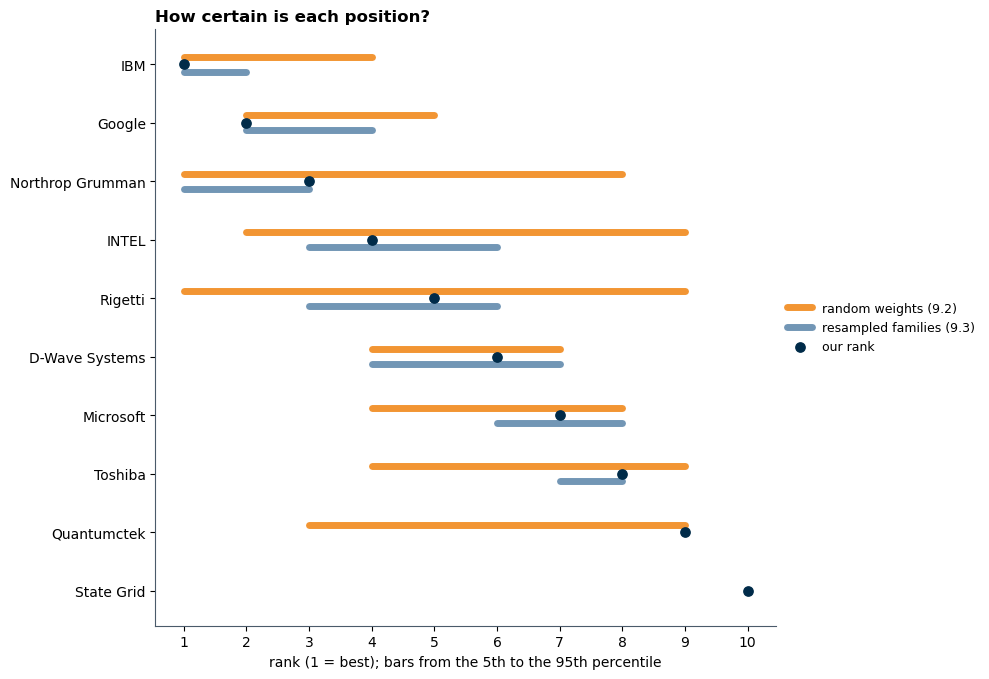

In [47]:
order = firms.sort_values("rank").index
fig, ax = plt.subplots(figsize=(10, 0.55 * len(order) + 1.4))
for y, f in enumerate(order):
    ax.plot([mc.loc[f, "rank 5%"], mc.loc[f, "rank 95%"]], [y - 0.13] * 2, color=ORANGE, lw=5, alpha=0.8,
            solid_capstyle="round", label="random weights (9.2)" if y == 0 else None)
    ax.plot([bs.loc[f, "rank 5%"], bs.loc[f, "rank 95%"]], [y + 0.13] * 2, color=BLUE, lw=5, alpha=0.8,
            solid_capstyle="round", label="resampled families (9.3)" if y == 0 else None)
    ax.scatter(firms.loc[f, "rank"], y, color=NAVY, zorder=3, s=45, label="our rank" if y == 0 else None)
ax.set_yticks(range(len(order)), [SHORT[f] for f in order])
ax.set_ylim(len(order) - 0.4, -0.6)
ax.set_xticks(range(1, len(TOP) + 1))
ax.set_xlabel("rank (1 = best); bars from the 5th to the 95th percentile")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("How certain is each position?")
plt.tight_layout()
plt.savefig(OUT / "fig_rank_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading it.** The blue bars (resampled families) are much shorter than the orange ones (random weights): **our ranking is more sensitive to the weights than to the data**. With the families resampled:

- IBM, Google and Northrop Grumman form a top group (in the top 3 in 100%, 91% and 96% of the resamples), but the order inside it is not certain: Northrop Grumman moves between 1st and 3rd, Google between 2nd and 4th;
- Intel, Rigetti and D-Wave form a middle group (ranks 3 to 7) that the data cannot order;
- Microsoft and Toshiba (6th to 8th) follow, and QuantumCTek (9th) and State Grid (10th) never move.

So the honest way to report the present score is in **three tiers** rather than ten positions: **leaders** (IBM, Google, Northrop Grumman), **challengers** (Intel, Rigetti, D-Wave) and **followers** (Microsoft, Toshiba, QuantumCTek, State Grid).

## 10. Using a refinement in the score

A refinement can **replace** a basic indicator (a better measure of the same thing) or be **added** as a fifth one. We pick the ones that make sense for quantum computing and for Dell, and test them against our basic score:

| Variant | Type | Why for our sector |
|---|---|---|
| **quadrilateral instead of offices** (7.3) | replace globalization | the Clarivate measure: it values the four main markets, not the number of offices |
| **foreign reach instead of offices** (7.4) | replace globalization | separates firms that protect abroad from domestic-only filers, the real split of our sector |
| **influence on 3 years** (5.2) | replace influence | in a fast-moving technology a short window measures how fast the others notice a patent |
| **plus blocking patents** (5.4) | add, 10% | blocking power is what matters for freedom to operate: an acquirer buys the right to stop others |
| **plus links to science** (5.5) | add, 10% | quantum computing grew out of physics labs: inventions close to research tend to be more radical |

An added indicator takes its weight proportionally from the other four, so that the weights still sum to 1. We leave out the EP validation states (7.2): they describe only the 14% of families with a granted EP patent, and for half of our firms a handful of patents.

In [48]:
def replace(weights, old, new):
    "Same weights, with indicator `old` replaced by `new`."
    return {(new if k == old else k): v for k, v in weights.items()}


def add(weights, new, w_new):
    "Add indicator `new` with weight w_new; the other weights shrink proportionally."
    return {**{k: v * (1 - w_new) for k, v in weights.items()}, new: w_new}


table = pd.concat([firms[INDICATORS], extras], axis=1)
variants = {
    "basic (ours)": WEIGHTS,
    "quadrilateral instead of offices": replace(WEIGHTS, "globalization", "quadrilateral_share"),
    "foreign reach instead of offices": replace(WEIGHTS, "globalization", "foreign_share"),
    "influence on 3 years": replace(WEIGHTS, "influence", "influence_3y"),
    "plus blocking patents": add(WEIGHTS, "blocking_share", 0.10),
    "plus links to science": add(WEIGHTS, "science_citations", 0.10),
}
compare = pd.DataFrame({name: final_rank(combine(table, w, METHOD)) for name, w in variants.items()})
display(compare.rename(index=SHORT).sort_values("basic (ours)"))
compare.corr(method="spearman")["basic (ours)"].drop("basic (ours)").round(2).to_frame("correlation with our ranking")

,basic (ours),quadrilateral instead of offices,foreign reach instead of offices,influence on 3 years,plus blocking patents,plus links to science
firm,,,,,,
IBM,1,1,2,1,2,1
Google,2,2,3,4,1,2
Northrop Grumman,3,7,6,2,3,3
INTEL,4,4,4,3,5,6
Rigetti,5,5,5,6,4,4
D-Wave Systems,6,3,1,5,6,5
Microsoft,7,6,8,7,7,7
Toshiba,8,9,7,8,8,8
Quantumctek,9,8,9,9,9,9


,correlation with our ranking
quadrilateral instead of offices,0.83
foreign reach instead of offices,0.77
influence on 3 years,0.95
plus blocking patents,0.98
plus links to science,0.96


**Reading it.** Three refinements leave the ranking almost as it is (correlations 0.95 to 0.98: 3-year window, blocking patents, links to science). The two other measures of globalization move it more (0.83 and 0.77), and always because of the same two firms:

- **Northrop Grumman** falls from 3rd to 7th with the quadrilateral share and to 6th with foreign reach: the first misses its "everywhere but China" strategy (7.3), the second discounts it because the US is its home;
- **D-Wave** rises to 3rd, and even 1st with foreign reach, because as a Canadian firm it is "abroad" as soon as it files in the US (7.4).

These moves come from the limits of the measures we saw in section 7, not from new information about the firms, so we keep **offices per family** in the score. The other refinements confirm the top group: with blocking patents Google becomes 1st (22% of its families are blocking, 5.4), with a 3-year window Northrop Grumman climbs to 2nd (its patents are noticed quickly).

**Our decision:** the basic score stays as it is. The refinements go into the deck as context for single firms (Northrop Grumman's choice to stay out of China, Rigetti's blockbuster patents, Google's blocking power), where they explain a position better than an extra weight would.

## 11. The present score for the Magic Quadrant

The score is one of the two axes of the Magic Quadrant (Step 5), next to the future score of Step 4. We save:

- `present_score.csv`: one row per scored firm with the basic indicators, the score, the rank and all the refinements;
- `present_score_robustness.csv`: the rank ranges of section 9;
- `present_score_design.json`: every design decision of this notebook (window, firms, weights, method), so that Step 5 and the technical appendix read them from one place.

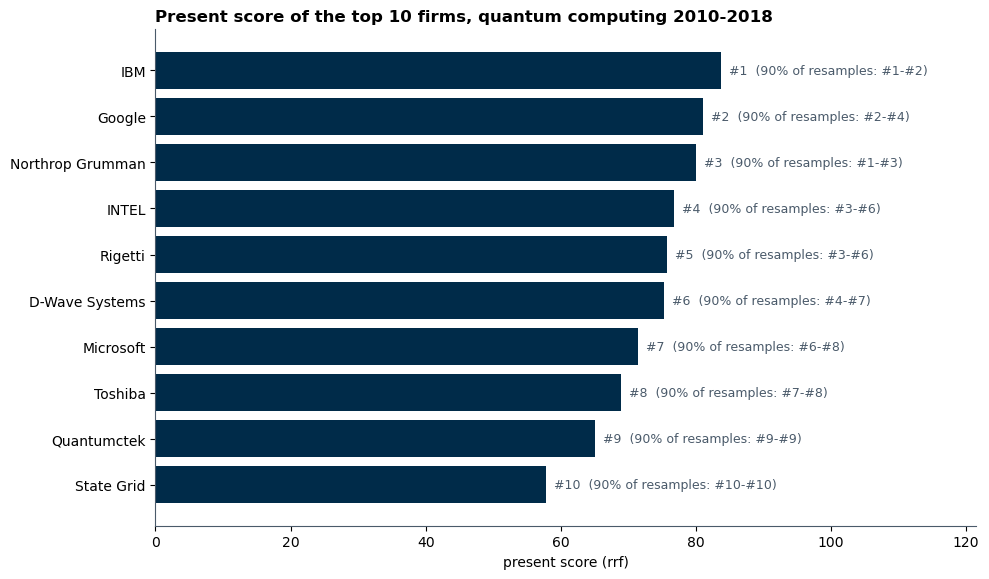

Saved to /home/jovyan/team-30-QuantumComputing/notebooks/outputs/step3


In [49]:
import json

present = pd.concat([firms, extras], axis=1)
present.insert(0, "short_name", [SHORT[f] for f in present.index])
present.sort_values("rank").to_csv(OUT / "present_score.csv")

robustness = pd.concat([mc.add_prefix("weights: "), bs.drop(columns="our rank").add_prefix("families: ")], axis=1)
robustness.sort_values("weights: our rank").to_csv(OUT / "present_score_robustness.csv")

design = {
    "env": ENV, "window": list(WINDOW), "n_firms": N_FIRMS, "min_families": MIN_FAMILIES,
    "indicators": {"volume": "share of the sector's families in the window",
                   "influence": "forward citations within 5 years / mean of the same priority year",
                   "success": "granted / national applications (no WO, no kind T), all offices",
                   "globalization": "mean distinct offices per family (no WO, no kind T)"},
    "weights": WEIGHTS, "method": METHOD, "rrf_c": RRF_C,
    "robustness": {"random_weight_draws": N_DRAWS, "bootstrap_resamples": B, "seed": 30},
}
(OUT / "present_score_design.json").write_text(json.dumps(design, indent=2))

fig, ax = plt.subplots(figsize=(10, 0.45 * len(TOP) + 1.4))
final = firms.sort_values("score")
ax.barh([SHORT[f] for f in final.index], final.score, color=NAVY)
for y, f in enumerate(final.index):
    ax.text(final.loc[f, "score"], y, f"  #{final.loc[f, 'rank']}  (90% of resamples: "
            f"#{bs.loc[f, 'rank 5%']:.0f}-#{bs.loc[f, 'rank 95%']:.0f})", va="center", fontsize=9, color=GREY)
ax.set_xlim(0, final.score.max() * 1.45)
ax.set_xlabel(f"present score ({METHOD})")
ax.set_title(f"Present score of the top {len(TOP)} firms, quantum computing {WINDOW[0]}-{WINDOW[1]}")
plt.tight_layout()
plt.savefig(OUT / "fig_present_score.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved to", OUT.resolve())

### Design decisions, for the technical appendix

| Decision | Our choice | Section |
|---|---|---|
| Unit | DOCDB family; applicants harmonised with `prepare_applicants`, firms only | 2, 3 |
| Window | priority years 2010-2018 | 2.1 |
| Firms scored | top 10 by families in the window, at least 10 families | 3.1 |
| Volume | share of the sector's families in the window | 4.1 |
| Influence | forward citations within 5 years ÷ mean of the same priority year | 5.1 |
| Success | granted ÷ national applications at all offices (no `WO`, no kind `T`) | 6.1 |
| Globalization | mean distinct offices per family (no `WO`, no kind `T`) | 7.1 |
| Method | Reciprocal Rank Fusion, $c$ = 10 | 8.3, 8.5 |
| Weights | influence 0.35, globalization 0.25, volume 0.20, success 0.20 | 8.4 |
| Robustness | 3 methods, 8 sets of weights by hand, 2,000 random sets, 1,000 bootstrap resamples | 9 |

### What the present score tells Dell

1. **Three leaders, robust to the method, the weights and the data: IBM, Google and Northrop Grumman.** IBM is the only firm that is good on every dimension; Google and Northrop Grumman add strong influence to the widest protection of the sector. The order inside the group should not be over-read (9.3).
2. **Influence without protection: Rigetti and Intel.** They own the most cited patents of the sector, and Rigetti the highest share of blocking ones, but they protect them in few countries (and Intel has the lowest grant rate). Their present value is technological more than legal: if they extend their protection their position will change, which makes them a natural case for the future score.
3. **Big, but at home only: QuantumCTek and State Grid.** Large portfolios, protected almost only in China and little cited. On patent grounds they are not targets for Dell.
4. **The present score looks backwards.** It reads what already happened to patents filed in 2010-2018. The firms that exploded after 2018 are not in it: Origin Quantum (14 families in our window, 546 in 2019-2022), IonQ (13 vs 109) and Baidu (0 vs 179). They are the entrants that Step 4 has to catch.